# CC3092 – Deep Learning · Laboratorio 10
## Explicabilidad: Grad-CAM / CAM (visión) y SHAP / LIME / contrafactuales
### José Antonio Mérida Castejón - 201105

## Uso de IA
El uso de IA abarcó el "scaffolding" del notebook (estructura, datos, tablas y gráficas), la implementación completa del Task 4, la revisión del texto y la transcripción al informe. Los algoritmos centrales de los Tasks 1 a 3 y el análisis de resultados son de mi autoría. El detalle está en el archivo `AI.md`.


In [1]:
# Entorno local: `pip install -r requirements.txt` dentro del .venv (ver README). En Colab, descomente:
# %pip install -q shap
import shap  # falla aquí si el kernel no es el del .venv


In [2]:
import os, time, random, itertools, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

import torch
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image

from sklearn.datasets import fetch_openml
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.inspection import permutation_importance

import shap

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed()
print("Semilla:", SEED)
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| shap", shap.__version__)
DEVICE = "cpu"   # ResNet-18 con 3 imágenes corre bien en CPU; así los resultados son deterministas

Semilla: 42
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | shap 0.54.1


---
# Task 1 (Entrega Parcial) — Grad-CAM y CAM sobre ResNet-18
## Task 1.1 · Modelo, preprocesamiento e imágenes

In [3]:
# ResNet-18 con pesos de ImageNet, en modo evaluación (BatchNorm usa estadísticas fijas, sin dropout).
weights = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=weights).to(DEVICE).eval()
CLASSES = weights.meta["categories"]           # 1000 nombres de clase de ImageNet

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
# Preprocesamiento pedido: lado corto -> 256, recorte central 224x224, normalización por canal.
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Misma geometría pero sin normalizar: es la imagen 224x224 "visible" sobre la que se superponen mapas.
to_224_rgb = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

def bbox_to_224(bbox, orig_w, orig_h):
    # Lleva un recuadro (x0, y0, x1, y1) de la imagen original al sistema de coordenadas de 224x224,
    # reproduciendo exactamente Resize(256) + CenterCrop(224) de torchvision.
    short, long_ = min(orig_w, orig_h), max(orig_w, orig_h)
    s = 256 / short
    new_long = int(256 * long_ / short)
    new_w, new_h = (256, new_long) if orig_w <= orig_h else (new_long, 256)
    off_x = int(round((new_w - 224) / 2.0)); off_y = int(round((new_h - 224) / 2.0))
    x0, y0, x1, y1 = bbox
    out = [x0 * (new_w / orig_w) - off_x, y0 * (new_h / orig_h) - off_y,
           x1 * (new_w / orig_w) - off_x, y1 * (new_h / orig_h) - off_y]
    return tuple(int(np.clip(round(v), 0, 224)) for v in out)

### Imágenes

Las tres imágenes se arman con fotos incluidas en `scikit-image` y `scikit-learn`.

| Imagen | Contenido por defecto | Fuente |
|---|---|---|
| (a) objeto claro y centrado | taza de café (`skimage.data.coffee`) | Foto de Rachel Michetti, dominio público (CC0), incluida en scikit-image |
| (b) dos objetos de clases distintas | gato (`skimage.data.chelsea`) + taza de café, compuestos lado a lado | Gato "Chelsea": foto de Stéfan van der Walt (dominio público), scikit-image; taza: ídem (a) |
| (c) objeto fuera de contexto | la taza pegada sobre un paisaje con un templo (`china.jpg`) | `sklearn.datasets.load_sample_image("china.jpg")`, licencia CC BY 2.0 (Flickr), incluida en scikit-learn |

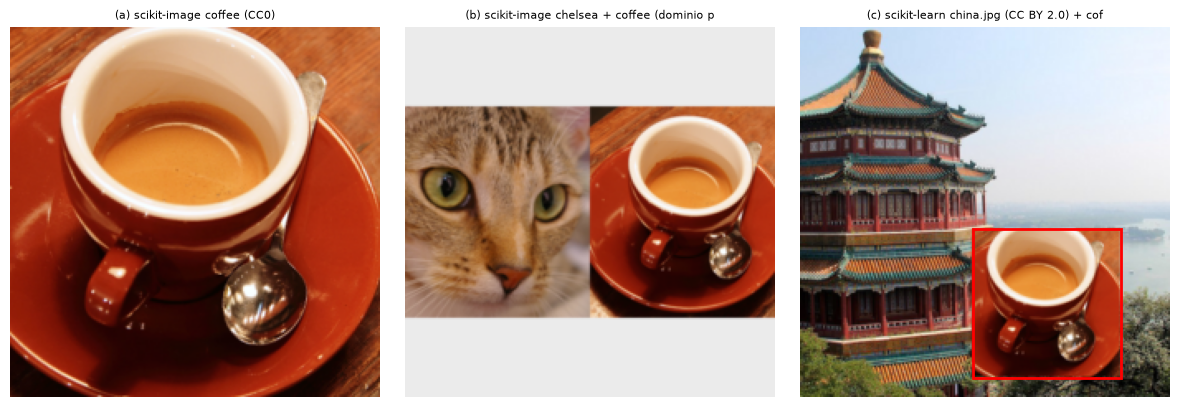

Recuadro del objeto en (c), coordenadas 224x224 (x0, y0, x1, y1): (104, 122, 194, 212)


In [4]:
from skimage import data as skdata
from sklearn.datasets import load_sample_image
coffee = skdata.coffee()                    # 400 x 600 x 3
cat    = skdata.chelsea()                   # 300 x 451 x 3
china  = load_sample_image("china.jpg")     # 427 x 640 x 3

# (a) Taza centrada: recorte cuadrado alrededor de la taza.
img_a = Image.fromarray(coffee[:, 100:500])

# (b) Lienzo cuadrado 512x512: gato a la izquierda, taza a la derecha (cuadrado para que el
#     CenterCrop no recorte a ninguno de los dos).
canvas = Image.new("RGB", (512, 512), (235, 235, 235))
canvas.paste(Image.fromarray(cat[:, 75:375]).resize((256, 256)), (0, 128))
canvas.paste(Image.fromarray(coffee[:, 100:500]).resize((256, 256)), (256, 128))
img_b = canvas

# (c) Taza pequeña pegada sobre el paisaje del templo (contexto inusual).
bg = Image.fromarray(china[:, 106:533])                   # 427 x 427
cup = Image.fromarray(coffee[40:360, 140:460]).resize((150, 150))
px, py = 200, 230                                          # esquina superior izquierda del pegado
bg.paste(cup, (px, py))
img_c = bg
BBOX_C_ORIG = (px, py, px + 150, py + 150)

images  = {"a": img_a, "b": img_b, "c": img_c}
SOURCES = {"a": "scikit-image coffee (CC0)",
           "b": "scikit-image chelsea + coffee (dominio público), composición propia",
           "c": "scikit-learn china.jpg (CC BY 2.0) + coffee, composición propia"}
OBJ1_CLASSES = [281, 282, 283, 284, 285]       # tabby, tiger cat, Persian, Siamese, Egyptian cat
OBJ2_CLASSES = [504, 967, 968]                 # coffee mug, espresso, cup


BBOX_C = bbox_to_224(BBOX_C_ORIG, *images["c"].size)
x_in   = {k: preprocess(im).unsqueeze(0).to(DEVICE) for k, im in images.items()}
rgb224 = {k: np.asarray(to_224_rgb(im)).astype(np.float32) / 255.0 for k, im in images.items()}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, k in zip(axes, "abc"):
    ax.imshow(rgb224[k]); ax.set_title(f"({k}) {SOURCES[k][:40]}", fontsize=8); ax.axis("off")
x0, y0, x1, y1 = BBOX_C
axes[2].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="red", lw=2))
plt.tight_layout(); plt.show()
print("Recuadro del objeto en (c), coordenadas 224x224 (x0, y0, x1, y1):", BBOX_C)

In [5]:
@torch.no_grad()
def topk(x, k=5):
    p = F.softmax(model(x), dim=1)[0]
    v, i = p.topk(k)
    return [(int(c), CLASSES[c], float(pv)) for pv, c in zip(v, i)]

TOP5 = {}
for k in "abc":
    TOP5[k] = topk(x_in[k])
    print(f"\nImagen ({k}) — top-5")
    for idx, name, p in TOP5[k]:
        print(f"   {idx:4d}  {name:30s}  p = {p:.4f}")
TOP1 = {k: TOP5[k][0][0] for k in "abc"}


Imagen (a) — top-5
    967  espresso                        p = 0.8517
    960  chocolate sauce                 p = 0.0403
    925  consomme                        p = 0.0391
    809  soup bowl                       p = 0.0255
    968  cup                             p = 0.0202

Imagen (b) — top-5
    968  cup                             p = 0.1756
    285  Egyptian cat                    p = 0.0924
    281  tabby                           p = 0.0915
    967  espresso                        p = 0.0867
    633  loupe                           p = 0.0387

Imagen (c) — top-5
    442  bell cote                       p = 0.2736
    698  palace                          p = 0.2044
    538  dome                            p = 0.0511
    832  stupa                           p = 0.0480
    449  boathouse                       p = 0.0466


**Comentario 1.1.** En (a) el modelo acierta con seguridad (*espresso*, ≈ 0.85). En (b) reparte la probabilidad entre los dos objetos (*cup* ≈ 0.18, gatos ≈ 0.09 cada uno), y en (c) predice la escena (*bell cote* ≈ 0.27, *palace* ≈ 0.20) en lugar de la taza. El recuadro de la taza en (c) es $(104, 122, 194, 212)$ en la imagen de $224\times224$.

## Task 1.2 · Grad-CAM desde cero (layer4)

$\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial y^c}{\partial A^k_{ij}}$, $\;L^c = \mathrm{ReLU}\big(\sum_k \alpha_k^c A^k\big)$, con $y^c$ el **logit** (antes del softmax).

In [6]:
class GradCAM:
    # Grad-CAM con dos hooks sobre una capa:
    #   - forward hook  -> guarda las activaciones A (1, 512, 7, 7)
    #   - backward hook -> guarda dy^c/dA (mismo tamaño)
    def __init__(self, model, layer):
        self.model, self.A, self.G = model, None, None
        self.h_fwd = layer.register_forward_hook(self._fwd)
        self.h_bwd = layer.register_full_backward_hook(self._bwd)

    def _fwd(self, module, inp, out):
        self.A = out.detach()

    def _bwd(self, module, grad_in, grad_out):
        self.G = grad_out[0].detach()          # dy^c / dA  (gradiente respecto a la SALIDA de layer4)

    def __call__(self, x, c):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(x)                 # (1, 1000) logits, sin softmax
        logits[0, c].backward()                # retropropaga desde y^c (logit), no desde prob ni pérdida
        A, G = self.A[0], self.G[0]            # (512, 7, 7)
        alpha = G.mean(dim=(1, 2))             # alpha_k^c = promedio espacial del gradiente del canal k
        L_raw = (alpha[:, None, None] * A).sum(0)        # sum_k alpha_k A^k  (7x7, sin ReLU)
        L = F.relu(L_raw)                                 # ReLU
        up = F.interpolate(L[None, None], size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
        up = (up - up.min()) / (up.max() - up.min() + 1e-12)   # normalización min-max
        return {"logit": float(logits[0, c].detach()), "alpha": alpha, "A": A, "G": G,
                "L_raw": L_raw.detach(), "L7": L.detach(), "map224": up.detach().cpu().numpy()}

    def remove(self):
        self.h_fwd.remove(); self.h_bwd.remove()

gradcam = GradCAM(model, model.layer4)

def overlay(ax, rgb, heat, title, bbox=None):
    ax.imshow(rgb); ax.imshow(heat, cmap="jet", alpha=0.45); ax.set_title(title, fontsize=9); ax.axis("off")
    if bbox is not None:
        x0, y0, x1, y1 = bbox
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="white", lw=2))

(b) top-1: cup  |  segundo objeto: Egyptian cat  (p = 0.0924)


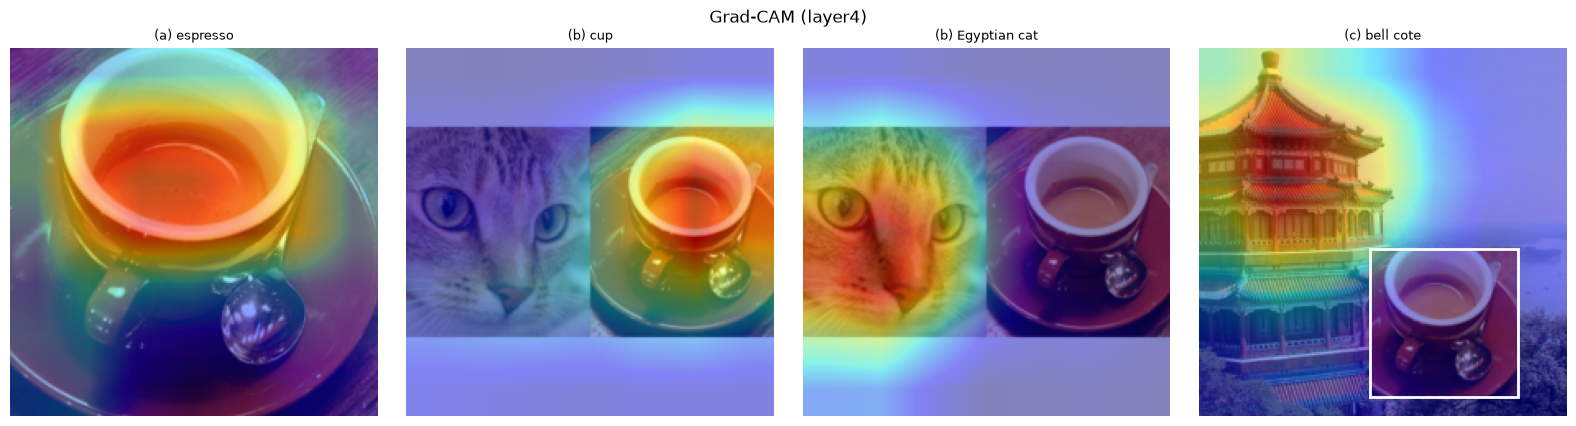

In [7]:
# Clase del segundo objeto de (b): la de mayor probabilidad dentro de cada grupo de clases.
with torch.no_grad():
    pb = F.softmax(model(x_in["b"]), 1)[0]
C_B1 = max(OBJ1_CLASSES, key=lambda c: pb[c].item())
C_B2 = max(OBJ2_CLASSES, key=lambda c: pb[c].item())
# El "segundo objeto" es el del grupo que NO contiene la clase top-1.
C_B_SECOND = C_B2 if TOP1["b"] in OBJ1_CLASSES else C_B1
print(f"(b) top-1: {CLASSES[TOP1['b']]}  |  segundo objeto: {CLASSES[C_B_SECOND]}  (p = {pb[C_B_SECOND]:.4f})")

GC = {k: gradcam(x_in[k], TOP1[k]) for k in "abc"}
GC["b2"] = gradcam(x_in["b"], C_B_SECOND)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
overlay(axes[0], rgb224["a"], GC["a"]["map224"], f"(a) {CLASSES[TOP1['a']]}")
overlay(axes[1], rgb224["b"], GC["b"]["map224"], f"(b) {CLASSES[TOP1['b']]}")
overlay(axes[2], rgb224["b"], GC["b2"]["map224"], f"(b) {CLASSES[C_B_SECOND]}")
overlay(axes[3], rgb224["c"], GC["c"]["map224"], f"(c) {CLASSES[TOP1['c']]}", bbox=BBOX_C)
plt.suptitle("Grad-CAM (layer4)"); plt.tight_layout(); plt.show()

**Comentario 1.2.** En (a) el mapa cubre la taza; en (b) cada clase ilumina su propio objeto (taza a la derecha, gato a la izquierda); en (c) el mapa se concentra en el templo y casi no toca la taza dentro del recuadro.

## Task 1.3 · CAM desde los pesos de `fc` y relación con Grad-CAM

ResNet-18: $y^c = \frac{1}{Z}\sum_{i,j}\sum_k w_k^c A^k_{ij} + b_c$ (GAP + lineal), con $Z = 49$. CAM: $M^c_{ij} = \sum_k w_k^c A^k_{ij}$.

In [8]:
Z = 49
W_fc, b_fc = model.fc.weight.detach(), model.fc.bias.detach()

def minmax(t):
    return (t - t.min()) / (t.max() - t.min() + 1e-12)

rows = []
for k in ["a", "b", "b2", "c"]:
    c = TOP1["b"] if k == "b" else (C_B_SECOND if k == "b2" else TOP1[k])
    A = GC[k]["A"]                                   # activaciones capturadas por el forward hook
    M = torch.einsum("k,kij->ij", W_fc[c], A)        # (a) M^c = sum_k w_k^c A^k   (sin gradientes)
    score = M.sum() / Z + b_fc[c]                    # (b) (1/Z) sum_ij M_ij + b_c  ==  y^c
    ZL = Z * GC[k]["L_raw"]                          # (c) Z * L^c sin ReLU ni normalización
    err_c = (ZL - M).abs().max().item()
    m_cam, m_gc = minmax(F.relu(M)), minmax(F.relu(GC[k]["L_raw"]))   # (d) ReLU + min-max en 7x7
    err_d = (m_cam - m_gc).abs().max().item()
    rows.append({"imagen": k, "clase": CLASSES[c], "logit y^c": GC[k]["logit"],
                 "(1/Z)ΣM + b": score.item(), "|error| (b)": abs(score.item() - GC[k]["logit"]),
                 "max|Z·L − M| (c)": err_c, "max|norm| (d)": err_d})
T13 = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.3e}" if abs(v) < 1e-3 and v != 0 else f"{v:.6f}")
T13

,imagen,clase,logit y^c,(1/Z)ΣM + b,|error| (b),max|Z·L − M| (c),max|norm| (d)
0,a,espresso,15.616573,15.616572,9.537e-07,1.335e-05,5.364e-07
1,b,cup,9.193426,9.193426,0.000000,1.144e-05,4.172e-07
2,b2,Egyptian cat,8.551533,8.551534,9.537e-07,1.335e-05,5.364e-07
3,c,bell cote,9.498821,9.498820,9.537e-07,7.629e-06,4.768e-07


**Comentario 1.3.** En las cuatro comprobaciones los errores son de $\lesssim10^{-5}$ (precisión de float32): la descomposición del logit se cumple, $Z\,L^c = M^c$ y los mapas normalizados coinciden. Es decir, en este ResNet Grad-CAM y CAM son el mismo mapa salvo la constante $Z$.

## Task 1.4 · Preguntas
### (a) $\alpha_k^c$ vs $w_k^c/Z$ en la imagen (a)

In [9]:
c = TOP1["a"]
alpha_a = GC["a"]["alpha"]
w_over_Z = W_fc[c] / Z
top5_ch = torch.argsort(W_fc[c], descending=True)[:5]       # 5 canales de mayor peso w_k^c
T14a = pd.DataFrame({
    "canal k": top5_ch.tolist(),
    "w_k^c": W_fc[c][top5_ch].tolist(),
    "alpha_k^c (Grad-CAM)": alpha_a[top5_ch].tolist(),
    "w_k^c / Z": w_over_Z[top5_ch].tolist(),
})
T14a["error relativo"] = (T14a["alpha_k^c (Grad-CAM)"] - T14a["w_k^c / Z"]).abs() / T14a["w_k^c / Z"].abs()
print("Máx. error relativo sobre los 512 canales:",
      ((alpha_a - w_over_Z).abs() / w_over_Z.abs().clamp_min(1e-12)).max().item())
print("Épsilon de float32:", torch.finfo(torch.float32).eps)
# Además: el gradiente dy^c/dA_ij^k debería ser constante en (i,j) dentro de cada canal
G = GC["a"]["G"]
print("Máx. variación espacial del gradiente dentro de un canal:", (G.amax((1, 2)) - G.amin((1, 2))).abs().max().item())
T14a

Máx. error relativo sobre los 512 canales: 2.3810379445876606e-07
Épsilon de float32: 1.1920928955078125e-07
Máx. variación espacial del gradiente dentro de un canal: 0.0


,canal k,w_k^c,alpha_k^c (Grad-CAM),w_k^c / Z,error relativo
0,103,0.313723,0.006403,0.006403,0.000000
1,432,0.292427,0.005968,0.005968,0.000000
2,172,0.290122,0.005921,0.005921,7.865e-08
3,14,0.289247,0.005903,0.005903,7.889e-08
4,144,0.247431,0.005050,0.005050,9.222e-08


> **❓ Pregunta.** Compare $\alpha_k^c$ con $w_k^c/Z$ en los 5 canales de mayor peso (imagen a) y reporte el error relativo. ¿En qué paso de la derivación se usa que $\partial y^c/\partial A^k_{ij}$ es igual en todas las posiciones? ¿Por qué el error es del orden de la precisión de punto flotante y no cero?

**Respuesta 1.4(a).**

Se calculó $\alpha_k^c$ para la clase de la imagen (a) y se comparó con $w_k^c/Z$, donde $Z = 49$ es el número de posiciones espaciales. En los cinco canales de mayor peso, los dos valores son prácticamente iguales. Por ejemplo, en el canal 103 ambos dan aproximadamente $0.0064$. El error relativo en estos canales es menor a $10^{-7}$. Al revisar los 512 canales, el error máximo es de alrededor de $2\times10^{-7}$. Además, el gradiente es idéntico en todas las posiciones de un mismo canal.

Esto se explica por el *global average pooling* antes de la capa final. La salida de la clase es

$$y^c=\sum_k w_k^c\,\frac{1}{Z}\sum_{i,j}A^k_{ij}+b_c,$$

así que al derivar respecto a una activación se obtiene

$$\frac{\partial y^c}{\partial A^k_{ij}}=\frac{w_k^c}{Z}.$$

La derivada no depende de la posición $(i,j)$. Como el gradiente es constante dentro del canal, promediarlo no cambia nada, y entonces $\alpha_k^c = w_k^c/Z$. Es decir, en esta arquitectura Grad-CAM y CAM dan el mismo mapa, solo escalado por la constante $Z$.

Los errores no son exactamente cero porque PyTorch trabaja en float32, cuya precisión es de aproximadamente $1.2\times10^{-7}$. Al calcular el gradiente, PyTorch divide entre 49, multiplica por los pesos y luego promedia, en un orden distinto al del cálculo directo de $w_k^c/Z$. Cada una de esas operaciones redondea un poco. Por eso los errores son del mismo orden que la precisión de float32.

### (b) Discriminación entre las dos clases de la imagen (b)

Clases: cup  vs  Egyptian cat
IoU de los píxeles top-20%: 0.0000
  mapa clase 1: centro de masa (x, y) = (143.5, 111.7)
  mapa clase 2: centro de masa (x, y) = (57.6, 117.5)
Correlación de Spearman entre los dos mapas 7x7: -0.16463685879612705


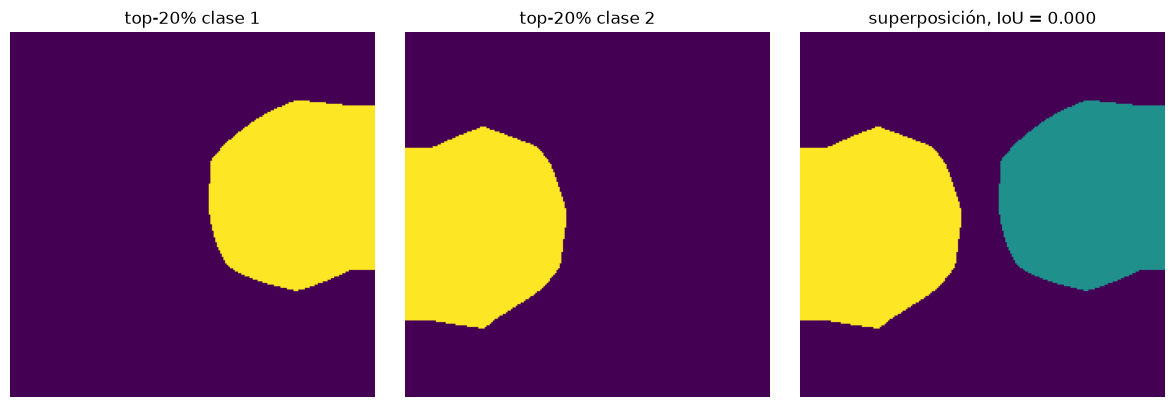

In [10]:
def top_frac_mask(m, frac=0.20):
    thr = np.quantile(m, 1 - frac)
    return m >= thr

m1, m2 = GC["b"]["map224"], GC["b2"]["map224"]
S1, S2 = top_frac_mask(m1), top_frac_mask(m2)
IoU_b = (S1 & S2).sum() / (S1 | S2).sum()
print(f"Clases: {CLASSES[TOP1['b']]}  vs  {CLASSES[C_B_SECOND]}")
print(f"IoU de los píxeles top-20%: {IoU_b:.4f}")
# Centro de masa de cada mapa (en píxeles 224) para ver si caen sobre objetos distintos
yy, xx = np.mgrid[0:224, 0:224]
for name, m in [("mapa clase 1", m1), ("mapa clase 2", m2)]:
    print(f"  {name}: centro de masa (x, y) = ({(m*xx).sum()/m.sum():.1f}, {(m*yy).sum()/m.sum():.1f})")
print("Correlación de Spearman entre los dos mapas 7x7:",
      spearmanr(GC["b"]["L7"].flatten().numpy(), GC["b2"]["L7"].flatten().numpy())[0])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(S1); axes[0].set_title("top-20% clase 1")
axes[1].imshow(S2); axes[1].set_title("top-20% clase 2")
axes[2].imshow(S1.astype(int) + 2 * S2.astype(int), cmap="viridis"); axes[2].set_title(f"superposición, IoU = {IoU_b:.3f}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

> **❓ Pregunta.** En la imagen (b), reporte el IoU entre el 20 % de píxeles más altos de los mapas de las dos clases. ¿El mapa discrimina entre clases? ¿Qué límite impone que cada posición cubra $32\times32$ px?

**Respuesta 1.4(b).**

El IoU entre las regiones top-20 % de *cup* y *Egyptian cat* es $0$. Es decir, las dos regiones no se tocan. Los centros de masa de cada mapa están en lados opuestos de la imagen: la taza en $x\approx143$ y el gato en $x\approx58$. Esto coincide con la posición real de cada objeto. Además, la correlación de Spearman entre los dos mapas de $7\times7$ es $-0.16$, así que tampoco hay una relación positiva entre ellos.

Por lo tanto, el mapa sí discrimina entre clases; cada clase resalta su propio objeto y no la misma zona. Vale la pena notar que las probabilidades del modelo son bajas (≈ $0.18$ para la taza y ≈ $0.09$ para el gato). Aun así, los mapas son claros, lo que muestra que Grad-CAM puede localizar bien aunque el modelo no esté muy seguro de su predicción.

Que cada posición cubra $32\times32$ px significa que el mapa no puede localizar nada con más precisión que un bloque de 32 px. Un objeto más pequeño que eso, o dos objetos a menos de 32 px de distancia, quedan dentro de la misma celda y el mapa no los puede separar. Escalar el mapa a $224\times224$ no lo arregla, porque la interpolación solo suaviza los bordes entre celdas y no agrega información.

### (c) Imagen (c): masa dentro del recuadro y prueba causal

Fracción de la masa del mapa dentro del recuadro: 0.0391  (el recuadro ocupa 0.1614 del área)

Clase: bell cote
  p original                     = 0.2736
  p con fondo gris (solo objeto) = 0.0000   Δ = -0.2736
  p con objeto gris (solo fondo) = 0.3530   Δ = +0.0794
  top-3 solo objeto: [('espresso', 0.814), ('cup', 0.038), ('coffee mug', 0.034)]
  top-3 solo fondo : [('palace', 0.4), ('bell cote', 0.353), ('monastery', 0.069)]


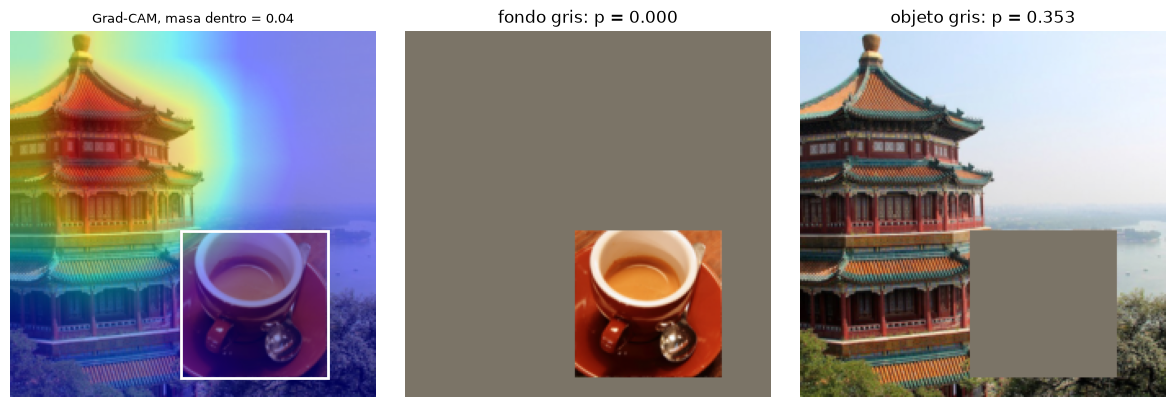

In [11]:
x0, y0, x1, y1 = BBOX_C
m = GC["c"]["map224"]
inside = np.zeros_like(m, dtype=bool); inside[y0:y1, x0:x1] = True
mass_in = m[inside].sum() / m.sum()
area_in = inside.mean()
print(f"Fracción de la masa del mapa dentro del recuadro: {mass_in:.4f}  (el recuadro ocupa {area_in:.4f} del área)")

# Prueba causal: "gris" = media de ImageNet, que tras normalizar es exactamente 0 en los 3 canales.
c = TOP1["c"]
inside_t = torch.from_numpy(inside).float()[None, None]      # (1,1,224,224)
x_obj_only = x_in["c"] * inside_t          # fondo -> gris (0 en espacio normalizado)
x_bg_only  = x_in["c"] * (1 - inside_t)    # objeto -> gris (control)
with torch.no_grad():
    p_orig = F.softmax(model(x_in["c"]), 1)[0]
    p_obj  = F.softmax(model(x_obj_only), 1)[0]
    p_bg   = F.softmax(model(x_bg_only), 1)[0]
print(f"\nClase: {CLASSES[c]}")
print(f"  p original                     = {p_orig[c]:.4f}")
print(f"  p con fondo gris (solo objeto) = {p_obj[c]:.4f}   Δ = {p_obj[c]-p_orig[c]:+.4f}")
print(f"  p con objeto gris (solo fondo) = {p_bg[c]:.4f}   Δ = {p_bg[c]-p_orig[c]:+.4f}")
print("  top-3 solo objeto:", [(CLASSES[i], round(float(p_obj[i]), 3)) for i in p_obj.topk(3).indices])
print("  top-3 solo fondo :", [(CLASSES[i], round(float(p_bg[i]), 3)) for i in p_bg.topk(3).indices])

def denorm(x):
    return (x[0].permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
overlay(axes[0], rgb224["c"], m, f"Grad-CAM, masa dentro = {mass_in:.2f}", bbox=BBOX_C)
axes[1].imshow(denorm(x_obj_only)); axes[1].set_title(f"fondo gris: p = {p_obj[c]:.3f}"); axes[1].axis("off")
axes[2].imshow(denorm(x_bg_only));  axes[2].set_title(f"objeto gris: p = {p_bg[c]:.3f}"); axes[2].axis("off")
plt.tight_layout(); plt.show()

> **❓ Pregunta.** En la imagen (c), ¿qué fracción de la masa del mapa cae dentro del recuadro? Haga la prueba causal (todo lo de fuera en gris) y diga si mapa y prueba coinciden en que el modelo usa el fondo. ¿Hay evidencia de atajo?

**Respuesta 1.4(c).**

Solo el ≈ 4 % de la masa del mapa cae dentro del recuadro, aunque el recuadro ocupa ≈ 16 % de la imagen. Es decir, el mapa le da al objeto menos atención de la que le tocaría al azar y se concentra en el fondo (el templo).

En la prueba causal, la probabilidad de *bell cote* es $0.27$ con la imagen original. Al poner el fondo en gris y dejar solo la taza, cae a $\approx 0$ y el modelo pasa a predecir *espresso* ($\approx 0.8$). Al poner la taza en gris y dejar solo el fondo, sube a $0.35$.

El mapa y la prueba coinciden, el modelo usa el fondo y no la taza. Quitar la taza no baja la predicción, mientras que quitar el fondo la elimina por completo.

Sí hay evidencia de atajo. El modelo clasifica la escena por su contexto e ignora el objeto. Además, el mapa (que es correlacional) y la intervención (que es causal) llegan a la misma conclusión, lo que la hace más confiable.

---
# Task 2 (Entrega Parcial) — SHAP sobre German Credit
## Task 2.1 · Datos y modelo

In [ ]:
datos = fetch_openml("credit-g", version=1, as_frame=True)
X_raw = datos.data.copy()
y = (datos.target == "good").astype(int).values        # good = 1, bad = 0

CAT_COLS = [c for c in X_raw.columns if str(X_raw[c].dtype) == "category"]
NUM_COLS = [c for c in X_raw.columns if c not in CAT_COLS]
print(f"{X_raw.shape[0]} filas, {len(NUM_COLS)} numéricas, {len(CAT_COLS)} categóricas")
print("Numéricas:", NUM_COLS)

# Codificación ordinal de las categóricas
oe = OrdinalEncoder()
X = X_raw.copy()
X[CAT_COLS] = oe.fit_transform(X_raw[CAT_COLS])
X = X.astype(float)
FEATURES = list(X.columns)

def decode(df_coded):
    # Devuelve una copia con las categóricas decodificadas a sus etiquetas originales.
    out = df_coded.copy().astype(object)
    out[CAT_COLS] = oe.inverse_transform(df_coded[CAT_COLS])
    return out

# División estratificada 80/20 con índices, para reutilizar exactamente la misma partición en 2.3 y 2.5.
idx = np.arange(len(X))
idx_tr, idx_te = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X.iloc[idx_tr].reset_index(drop=True), X.iloc[idx_te].reset_index(drop=True)
y_train, y_test = y[idx_tr], y[idx_te]

GB_PARAMS = dict(n_estimators=200, max_depth=3, random_state=SEED)
gb = GradientBoostingClassifier(**GB_PARAMS).fit(X_train, y_train)
p_test = gb.predict_proba(X_test)[:, 1]
print(f"\nExactitud (test): {accuracy_score(y_test, (p_test >= 0.5).astype(int)):.4f}")
print(f"AUC (test):       {roc_auc_score(y_test, p_test):.4f}")

1000 filas, 7 numéricas, 13 categóricas
Numéricas: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']



Exactitud (test): 0.7750
AUC (test):       0.7650


**Comentario 2.1.** El modelo alcanza una exactitud de ≈ 0.78 y un AUC de ≈ 0.77 en prueba: un desempeño moderado, suficiente para explicarlo pero sin mucho margen. Los códigos ordinales de las categóricas son arbitrarios y el modelo los trata como numéricos, lo cual limita la interpretación de esas variables.

## Task 2.2 · TreeSHAP intervencional

In [13]:
N_BG = 100
bg_idx = np.random.RandomState(SEED).choice(len(X_train), N_BG, replace=False)
background = X_train.iloc[bg_idx]

# Explicador de árboles intervencional sobre la salida cruda (log-odds) del GradientBoosting.
tree_exp = shap.TreeExplainer(gb, data=background, feature_perturbation="interventional", model_output="raw")
sv = tree_exp(X_test)
phi = sv.values                                   # (n_test, 20)
phi0 = float(np.ravel(tree_exp.expected_value)[0])
f_test = gb.decision_function(X_test)             # log-odds del modelo

# (a) Eficiencia: phi0 + sum_j phi_j = f(x)
eff_err = np.abs(phi0 + phi.sum(1) - f_test)
print(f"(a) Error absoluto máximo de eficiencia: {eff_err.max():.3e}")

# (b) Valor base = promedio de f sobre el fondo
f_bg_mean = gb.decision_function(background).mean()
print(f"(b) Valor base phi0 = {phi0:.6f}  |  promedio de f(fondo) = {f_bg_mean:.6f}  |  dif = {abs(phi0-f_bg_mean):.3e}")

(a) Error absoluto máximo de eficiencia: 9.520e-08
(b) Valor base phi0 = 1.334498  |  promedio de f(fondo) = 1.334498  |  dif = 0.000e+00


El error absoluto máximo de eficiencia es bastante pequeño ($\approx10^{-7}$), además la diferencia entre el valor base y el promedio de la salida en log-odds es prácticamente 0 (ambos $\approx1.33$). Todo cuadra.

In [14]:
# (c) Importancia global SHAP vs importancia por permutación (AUC, 10 repeticiones)
I_shap = pd.Series(np.abs(phi).mean(0), index=FEATURES, name="I_j SHAP")
perm = permutation_importance(gb, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED)
I_perm = pd.Series(perm.importances_mean, index=FEATURES, name="perm ΔAUC")

rank_shap = I_shap.rank(ascending=False).astype(int)
rank_perm = I_perm.rank(ascending=False).astype(int)
rho, pval = spearmanr(I_shap.values, I_perm.values)

print("Top-5 SHAP:       ", list(I_shap.sort_values(ascending=False).index[:5]))
print("Top-5 permutación:", list(I_perm.sort_values(ascending=False).index[:5]))
print(f"Spearman entre rankings completos: rho = {rho:.4f} (p = {pval:.3g})")

T22c = pd.concat([I_shap, rank_shap.rename("rank SHAP"), I_perm,
                  pd.Series(perm.importances_std, index=FEATURES, name="perm std"),
                  rank_perm.rename("rank perm")], axis=1).sort_values("rank SHAP")
T22c

Top-5 SHAP:        ['checking_status', 'credit_amount', 'purpose', 'duration', 'savings_status']
Top-5 permutación: ['checking_status', 'credit_amount', 'duration', 'credit_history', 'savings_status']
Spearman entre rankings completos: rho = 0.7023 (p = 0.000556)


,I_j SHAP,rank SHAP,perm ΔAUC,perm std,rank perm
checking_status,0.735485,1,0.119024,0.030137,1
credit_amount,0.487121,2,0.076452,0.013489,2
purpose,0.484318,3,0.003738,0.010604,12
duration,0.378244,4,0.058060,0.011974,3
savings_status,0.339725,5,0.026155,0.011215,5
age,0.292273,6,-0.005417,0.009607,20
credit_history,0.233932,7,0.039643,0.011225,4
installment_commitment,0.209753,8,0.009929,0.004863,7
residence_since,0.197658,9,0.002179,0.013286,13
other_payment_plans,0.181824,10,0.020119,0.003393,6


El Spearman entre rankings es 0.702, por lo cual ambos rankings están bastante correlacionados. Las cinco variables principales según SHAP son:

- `checking_status`
- `credit_amount`
- `purpose`
- `duration`
- `savings_status`

Según permutación son:

- `checking_status`
- `credit_amount`
- `duration`
- `credit_history`
- `savings_status`

Cliente aprobado: índice de test 50, p(good) = 0.9994
Cliente rechazado: índice de test 76, p(good) = 0.0517

APROBADO: f(x) = 7.499, phi0 = 1.334
       variable     valor  phi (log-odds)
        purpose  used car        1.546782
            age 53.000000        1.087879
residence_since  1.000000        1.014820


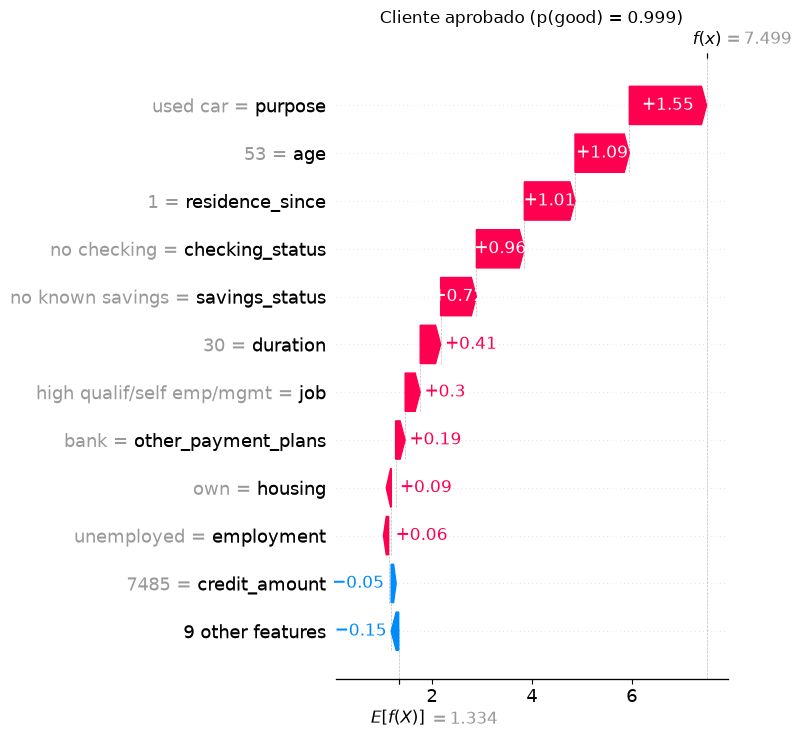


RECHAZADO: f(x) = -2.908, phi0 = 1.334
      variable      valor  phi (log-odds)
credit_history   all paid       -1.259218
savings_status     >=1000        1.027097
 credit_amount 433.000000       -0.992209


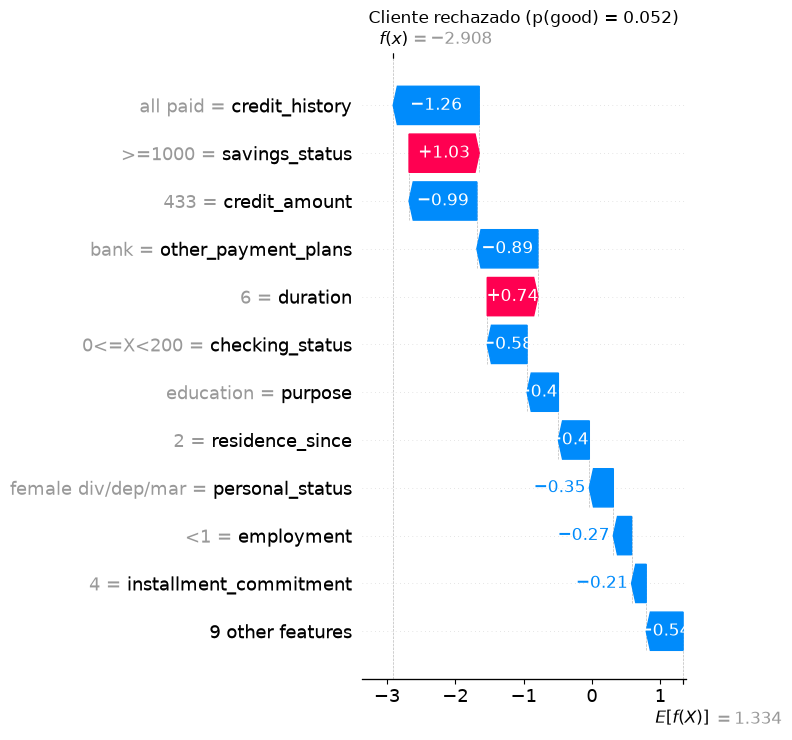

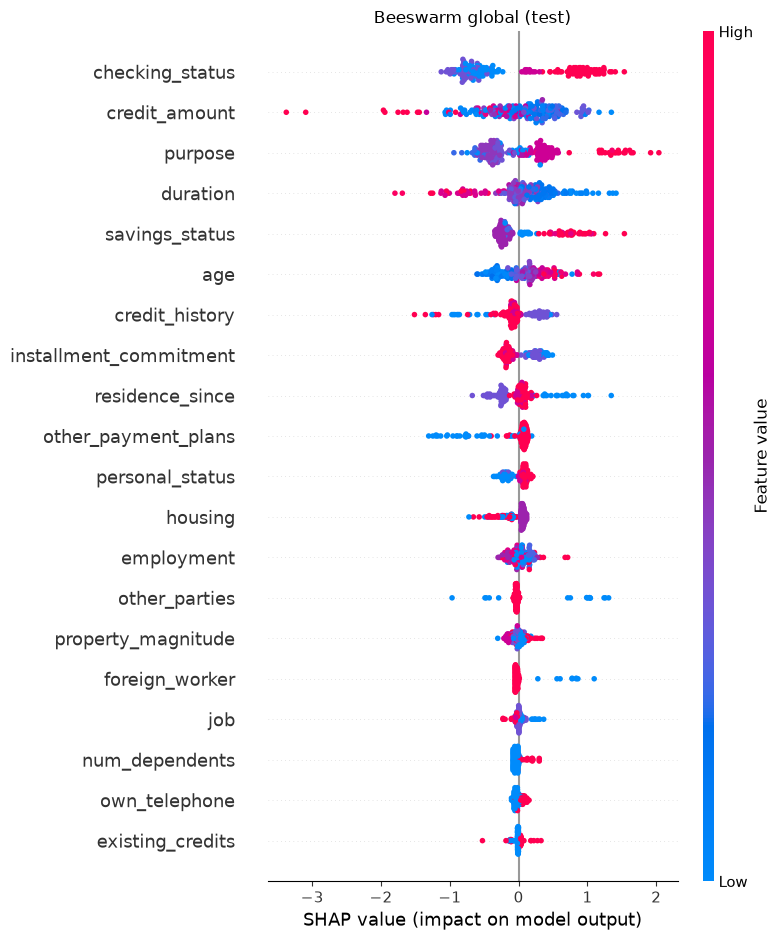

In [15]:
# (d) Cliente aprobado (p > 0.8) y rechazado (p < 0.2): se toma el más extremo de cada lado.
i_good = int(np.argmax(p_test)); i_bad = int(np.argmin(p_test))
assert p_test[i_good] > 0.8 and p_test[i_bad] < 0.2
print(f"Cliente aprobado: índice de test {i_good}, p(good) = {p_test[i_good]:.4f}")
print(f"Cliente rechazado: índice de test {i_bad}, p(good) = {p_test[i_bad]:.4f}")

X_test_dec = decode(X_test)
# Explanation con display_data para que los gráficos muestren las categorías reales en vez de códigos
sv = shap.Explanation(values=phi, base_values=np.full(len(phi), phi0), data=X_test.values,
                      display_data=X_test_dec.values, feature_names=FEATURES)

def top_contrib(i, n=3):
    order = np.argsort(-np.abs(phi[i]))[:n]
    return pd.DataFrame({"variable": [FEATURES[j] for j in order],
                         "valor": [X_test_dec.iloc[i, j] for j in order],
                         "phi (log-odds)": phi[i, order]})

for name, i in [("APROBADO", i_good), ("RECHAZADO", i_bad)]:
    print(f"\n{name}: f(x) = {f_test[i]:.3f}, phi0 = {phi0:.3f}")
    print(top_contrib(i).to_string(index=False))
    shap.plots.waterfall(sv[i], max_display=12, show=False)
    plt.title(f"Cliente {name.lower()} (p(good) = {p_test[i]:.3f})"); plt.tight_layout(); plt.show()

shap.plots.beeswarm(sv, max_display=20, show=False)
plt.title("Beeswarm global (test)"); plt.tight_layout(); plt.show()

> **❓ Pregunta.** Describa con palabras las tres contribuciones más grandes del cliente aprobado ($p>0.8$) y del rechazado ($p<0.2$).

**Respuesta 2.2(d).**

El valor base es $\phi_0 = 1.334$ log-odds, que equivale a ≈ 79 % de probabilidad de *good* para un cliente promedio.

El cliente aprobado (índice 50, $p = 0.999$) tiene tres contribuciones grandes, y las tres a favor. Que el préstamo sea para un carro usado suma $+1.55$, tener 53 años suma $+1.09$ y llevar 1 año en su residencia actual suma $+1.01$. Entre las tres aportan más de la mitad de lo que el cliente suma por encima de la base, y llevan la probabilidad casi a 1.

En el cliente rechazado (índice 76, $p = 0.052$), la contribución más grande es su historial de crédito "all paid", que resta $-1.26$. Le siguen tener ahorros de 1000 o más, que suma $+1.03$, y el monto del crédito (433), que resta $-0.99$. Los ahorros ayudan, pero no alcanzan: varias contribuciones negativas medianas, como `other_payment_plans` ($-0.89$) y `checking_status` ($-0.58$), terminan bajando el log-odds de $+1.33$ a $-2.91$.

Llama la atención que tener todo pagado *reduzca* la probabilidad de ser buen cliente. Es contraintuitivo, y refleja un patrón de los datos (y de una codificación ordinal arbitraria), no una regla de negocio razonable.

## Task 2.3 · Variable redundante (copia con ruido)

In [16]:
# Variable numérica de mayor I_j
VAR = I_shap[NUM_COLS].idxmax()
print("Variable duplicada:", VAR, "| I_j original =", round(I_shap[VAR], 5))

rng = np.random.RandomState(SEED)
X_dup = X.copy()
X_dup[VAR + "_copia"] = X[VAR] + 0.05 * X[VAR].std() * rng.randn(len(X))   # x_dup = x + 0.05 σ_x ε
print("Correlación de Pearson original-copia:", np.corrcoef(X_dup[VAR], X_dup[VAR + "_copia"])[0, 1])

Xd_train, Xd_test = X_dup.iloc[idx_tr].reset_index(drop=True), X_dup.iloc[idx_te].reset_index(drop=True)
gb_dup = GradientBoostingClassifier(**GB_PARAMS).fit(Xd_train, y_train)
print("AUC del modelo con copia:", roc_auc_score(y_test, gb_dup.predict_proba(Xd_test)[:, 1]))

j_o, j_c = list(X_dup.columns).index(VAR), list(X_dup.columns).index(VAR + "_copia")
configs = {
    "intervencional (fondo 100)": shap.TreeExplainer(gb_dup, data=Xd_train.iloc[bg_idx],
                                                     feature_perturbation="interventional", model_output="raw"),
    "tree_path_dependent":        shap.TreeExplainer(gb_dup, feature_perturbation="tree_path_dependent"),
}
rows = []
for name, ex in configs.items():
    ph = ex.shap_values(Xd_test)
    rows.append({"configuración": name,
                 "mean|φ_orig|": np.abs(ph[:, j_o]).mean(),
                 "mean|φ_copia|": np.abs(ph[:, j_c]).mean(),
                 "mean|φ_orig+φ_copia|": np.abs(ph[:, j_o] + ph[:, j_c]).mean(),
                 "I_j sin copia": I_shap[VAR]})
T23 = pd.DataFrame(rows); T23

Variable duplicada: credit_amount | I_j original = 0.48712
Correlación de Pearson original-copia: 0.9988030615678453
AUC del modelo con copia: 0.7617857142857144


,configuración,mean|φ_orig|,mean|φ_copia|,mean|φ_orig+φ_copia|,I_j sin copia
0,intervencional (fondo 100),0.302745,0.305953,0.500742,0.487121
1,tree_path_dependent,0.275249,0.293057,0.481337,0.487121


**Comentario 2.3.** El crédito de `credit_amount` se reparte casi por igual entre la variable y su copia (≈ 0.30 cada una en la intervencional y ≈ 0.28–0.29 en la de trayectoria), y la suma $|\phi_{orig}+\phi_{copia}|$ (≈ 0.50 y ≈ 0.48) queda cerca del $I_j$ sin copia (≈ 0.49). Cada una por separado parece menos importante de lo que es la variable original.

## Task 2.4 · KernelSHAP vs TreeSHAP

In [17]:
X10 = X_test.iloc[:10]
f_logodds = lambda Z_: gb.decision_function(pd.DataFrame(Z_, columns=FEATURES))   # salida en log-odds

rows = []
for nb in [10, 50, 100]:
    bg_n = background.iloc[:nb]                   # fondos anidados del mismo fondo aleatorio de 100
    # KernelSHAP (l1_reg=False: sin selección de variables, estima las 20)
    kex = shap.KernelExplainer(f_logodds, bg_n.values)
    t0 = time.perf_counter()
    phi_k = kex.shap_values(X10.values, nsamples=2000, l1_reg=False, silent=True)
    t_kernel = time.perf_counter() - t0
    # TreeSHAP intervencional con el mismo fondo
    tex = shap.TreeExplainer(gb, data=bg_n, feature_perturbation="interventional", model_output="raw")
    t0 = time.perf_counter()
    phi_t = tex.shap_values(X10)
    t_tree = time.perf_counter() - t0
    rows.append({"fondo": nb, "MAE Kernel vs Tree": np.abs(np.asarray(phi_k) - phi_t).mean(),
                 "max |err|": np.abs(np.asarray(phi_k) - phi_t).max(),
                 "t Kernel (s)": t_kernel, "t Tree (s)": t_tree,
                 "t Kernel / instancia (s)": t_kernel / 10})
T24 = pd.DataFrame(rows); T24

,fondo,MAE Kernel vs Tree,max |err|,t Kernel (s),t Tree (s),t Kernel / instancia (s)
0,10,0.002274,0.015904,0.256627,0.001362,0.025663
1,50,0.003953,0.025215,0.716983,0.005823,0.071698
2,100,0.003773,0.022986,1.356773,0.011065,0.135677


**Comentario 2.4.** KernelSHAP queda muy cerca de TreeSHAP con los tres fondos (error medio ≈ 0.002–0.004), y no mejora al aumentar el fondo. El tiempo sí crece con el fondo (≈ 0.25 s con 10, ≈ 0.7 s con 50 y ≈ 1.35 s con 100 instancias) y es mucho mayor que el de TreeSHAP (milisegundos).

## Task 2.5 · Shapley exacto escrito a mano (6 variables)

In [18]:
NUM6 = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
gb6 = GradientBoostingClassifier(**GB_PARAMS).fit(X_train[NUM6], y_train)
bg50 = X_train[NUM6].iloc[np.random.RandomState(SEED).choice(len(X_train), 50, replace=False)]

def exact_shapley(f, x, bg):
    # Shapley exacto con la función de valor intervencional:
    #   v(S) = (1/|B|) sum_{b in B} f(x_S, b_{N\S})     (los de S se fijan en x, el resto viene del fondo)
    #   phi_i = sum_{S ⊆ N\{i}} |S|! (n-|S|-1)! / n!  [v(S ∪ {i}) - v(S)]
    x = np.asarray(x, dtype=float); B = np.asarray(bg, dtype=float)
    n = len(x)
    masks = np.array(list(itertools.product([0, 1], repeat=n)), dtype=bool)     # 2^n coaliciones
    # Se evalúan las 2^n coaliciones en un solo lote: (2^n * |B|, n)
    Zs = np.where(masks[:, None, :], x[None, None, :], B[None, :, :])   # (2^n, |B|, n)
    v_vals = f(Zs.reshape(-1, n)).reshape(len(masks), len(B)).mean(1)
    v = {tuple(m): val for m, val in zip(masks, v_vals)}
    phi = np.zeros(n)
    for i in range(n):
        for m in masks:
            if m[i]: continue
            s = m.sum()
            w = math.factorial(s) * math.factorial(n - s - 1) / math.factorial(n)
            m_i = m.copy(); m_i[i] = True
            phi[i] += w * (v[tuple(m_i)] - v[tuple(m)])
    return phi, v[tuple([False] * n)], v[tuple([True] * n)]

f6 = lambda Z_: gb6.decision_function(pd.DataFrame(Z_, columns=NUM6))
tex6 = shap.TreeExplainer(gb6, data=bg50, feature_perturbation="interventional", model_output="raw")

rows = []
for i in range(5):
    x = X_test[NUM6].iloc[i].values
    phi_mine, v_empty, v_full = exact_shapley(f6, x, bg50)
    phi_lib = tex6.shap_values(X_test[NUM6].iloc[[i]])[0]
    rows.append({"instancia": i, "max|φ_propio − φ_shap|": np.abs(phi_mine - phi_lib).max(),
                 "Σφ": phi_mine.sum(), "v(N) − v(∅)": v_full - v_empty,
                 "|error eficiencia|": abs(phi_mine.sum() - (v_full - v_empty))})
T25 = pd.DataFrame(rows)
print("Error máximo global vs shap:", T25["max|φ_propio − φ_shap|"].max())
T25

Error máximo global vs shap: 2.130079468365409e-08


,instancia,max|φ_propio − φ_shap|,Σφ,v(N) − v(∅),|error eficiencia|
0,0,3.341e-09,0.252141,0.252141,2.220e-16
1,1,1.032e-08,-1.623512,-1.623512,0.000000
2,2,1.642e-08,-0.618297,-0.618297,4.441e-16
3,3,1.099e-08,1.448268,1.448268,2.220e-16
4,4,2.130e-08,0.080778,0.080778,7.355e-16


**Comentario 2.5.** El cálculo exacto con la fórmula de Shapley coincide con el explicador de árboles (error máximo ≈ $10^{-8}$) y los $\phi_i$ suman $v(N)-v(\emptyset)$ hasta precisión de máquina, así que la implementación es correcta.

## Task 2.6 · Preguntas
### (a) Aditividad en log-odds vs probabilidad (cliente rechazado)

In [19]:
sig = lambda t: 1 / (1 + np.exp(-t))
i = i_bad
p_x, p_base = sig(f_test[i]), sig(phi0)
indiv = sig(phi0 + phi[i]) - p_base                 # efecto individual de cada variable en probabilidad
print(f"p(x) = σ(f(x)) = {p_x:.4f}   |   σ(φ0) = {p_base:.4f}")
print(f"Σ_j [σ(φ0+φ_j) − σ(φ0)] = {indiv.sum():+.4f}")
print(f"p(x) − σ(φ0)            = {p_x - p_base:+.4f}")
print(f"Diferencia              = {indiv.sum() - (p_x - p_base):+.4f}")
pd.DataFrame({"φ_j (log-odds)": phi[i], "efecto en prob.": indiv}, index=FEATURES).sort_values("φ_j (log-odds)")

p(x) = σ(f(x)) = 0.0517   |   σ(φ0) = 0.7916
Σ_j [σ(φ0+φ_j) − σ(φ0)] = -0.9654
p(x) − σ(φ0)            = -0.7398
Diferencia              = -0.2256


,φ_j (log-odds),efecto en prob.
credit_history,-1.259218,-0.272773
credit_amount,-0.992209,-0.206837
other_payment_plans,-0.893143,-0.183002
checking_status,-0.582850,-0.112046
purpose,-0.458139,-0.085517
residence_since,-0.453006,-0.084452
personal_status,-0.351157,-0.063813
employment,-0.267099,-0.047482
installment_commitment,-0.214303,-0.037559
age,-0.121257,-0.020712


> **❓ Pregunta.** Para el cliente rechazado calcule $p(x)$, $\sigma(\phi_0)$ y $\sum_j[\sigma(\phi_0+\phi_j)-\sigma(\phi_0)]$; compárela con $p(x)-\sigma(\phi_0)$. ¿Por qué SHAP suma exacto en log-odds pero no en probabilidad?

**Respuesta 2.6(a).**

Para el cliente rechazado, $p(x) \approx 0.05$ y $\sigma(\phi_0) \approx 0.79$, así que la caída real es $p(x) - \sigma(\phi_0) \approx -0.74$. La suma de los efectos individuales en probabilidad da $\approx -0.97$. Es decir, sumar los efectos uno por uno exagera la caída en ≈ $0.23$.

SHAP suma exacto en log-odds porque esa es la función que explica: $f(x) = \phi_0 + \sum_j \phi_j$. En este caso el error es de $\sim10^{-7}$, o sea, cero en la práctica. Pero la probabilidad es $\sigma(f(x))$, y como la sigmoide no es lineal, el efecto de sumar todo junto no es igual a la suma de los efectos por separado.

La razón concreta es la pendiente de la sigmoide. Cada efecto individual se mide partiendo de $\phi_0$, donde la sigmoide es empinada, así que cada uno parece mover mucho la probabilidad. Pero cuando las contribuciones negativas se acumulan, el cliente llega a la cola de la sigmoide, donde la curva es plana y cada contribución adicional mueve muy poco la probabilidad. Por eso la suma individual sobreestima la caída real.

### (b) Mayor discrepancia de ranking SHAP vs permutación

In [20]:
diff = (rank_shap - rank_perm).abs().sort_values(ascending=False)
VAR_B = diff.index[0]
print(f"Variable con mayor diferencia: {VAR_B}  (rank SHAP {rank_shap[VAR_B]}, rank perm {rank_perm[VAR_B]})")
print(f"  I_j SHAP = {I_shap[VAR_B]:.4f}   ΔAUC perm = {I_perm[VAR_B]:.4f} ± {perm.importances_std[FEATURES.index(VAR_B)]:.4f}")
corr = X_train.corr(method="spearman")[VAR_B].drop(VAR_B)
print("\nCorrelaciones de Spearman con las demás variables (top-5 en |rho|):")
print(corr.reindex(corr.abs().sort_values(ascending=False).index).head(5).round(3).to_string())
print(f"\nNº de valores distintos de {VAR_B} en train: {X_train[VAR_B].nunique()}")

Variable con mayor diferencia: age  (rank SHAP 6, rank perm 20)
  I_j SHAP = 0.2923   ΔAUC perm = -0.0054 ± 0.0096

Correlaciones de Spearman con las demás variables (top-5 en |rho|):
housing           -0.312000
employment         0.306000
personal_status    0.273000
residence_since    0.245000
credit_history    -0.200000

Nº de valores distintos de age en train: 52


In [ ]:
# Respaldo de la hipótesis de sobreajuste: importancia por permutación (AUC) en train vs test
rows = []
for nombre, (Xs_, ys_) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
    pm = permutation_importance(gb, Xs_, ys_, scoring="roc_auc", n_repeats=10, random_state=SEED)
    rank_ = pd.Series(pm.importances_mean, index=FEATURES).rank(ascending=False).astype(int)
    for v_ in ["age", "purpose"]:
        k_ = FEATURES.index(v_)
        rows.append({"conjunto": nombre, "variable": v_, "ΔAUC": pm.importances_mean[k_],
                     "std": pm.importances_std[k_], "puesto": rank_[v_],
                     "AUC del modelo": roc_auc_score(ys_, gb.predict_proba(Xs_)[:, 1])})
print(pd.DataFrame(rows).round(3).to_string(index=False))


conjunto variable   ΔAUC   std  puesto  AUC del modelo
   train      age  0.025 0.003       5           0.990
   train  purpose  0.043 0.005       4           0.990
    test      age -0.005 0.010      20           0.765
    test  purpose  0.004 0.011      12           0.765


> **❓ Pregunta.** ¿Qué variable tiene la mayor diferencia de posición entre el ranking de $I_j$ y el de permutación? Proponga una hipótesis respaldada por datos y explique qué mide cada importancia.

**Respuesta 2.6(b).**

La variable con mayor diferencia es `age`. Está en el puesto 6 según SHAP ($I_j = 0.292$), pero en el puesto 20 según permutación, donde su efecto ($\Delta\text{AUC} = -0.005 \pm 0.010$) no se distingue de cero.

La hipótesis es que el modelo sobreajusta con `age`: la usa mucho, pero lo que aprende de ella no sirve para predecir en test. Se descarta que sea redundancia, porque `age` tiene poca correlación con las demás variables (la máxima es $|\rho| = 0.31$, con `housing`), así que ninguna otra la reemplaza al barajarla. En cambio, `age` tiene 52 valores distintos en train, lo que le permite al modelo hacer muchos cortes finos. Esos cortes le dan contribuciones grandes en SHAP, pero no mejoran el AUC en un test de solo 200 clientes, donde el ruido es de ±0.01. Lo respalda la importancia por permutación en train: `age` tiene $\Delta\text{AUC} = 0.025 \pm 0.003$ (puesto 5) frente a $-0.005 \pm 0.010$ en test (puesto 20), y el AUC del modelo pasa de 0.99 en train a 0.77 en test. `purpose` muestra el mismo patrón (puesto 3 en SHAP y 12 en permutación; $\Delta\text{AUC} = 0.043$ en train frente a $0.004$ en test).

Las dos importancias miden cosas distintas. $I_j = \frac{1}{N}\sum |\phi_j|$ mide cuánto mueve una variable la salida del modelo, en promedio, sin mirar las etiquetas. La importancia por permutación mide cuánto empeora el AUC en test cuando se rompe la relación de la variable con $y$. Por eso una variable puede mover mucho las predicciones del modelo y aun así no ayudar a predecir bien fuera de la muestra.

### (c) Crédito de la variable duplicada

> **❓ Pregunta.** Con la tabla del Task 2.3, ¿qué pasa con el crédito de la variable duplicada? ¿Qué axioma de Shapley esperaría que lo repartiera igual y por qué no lo hace exactamente? Compare las dos configuraciones y explique por qué la dependiente de la trayectoria no es exactamente la condicional. ¿Qué implica para interpretar SHAP como importancia real?

**Respuesta 2.6(c).**

Se duplicó `credit_amount`, que sin copia tenía $I_j \approx 0.49$. La correlación entre la original y la copia es $\approx 0.999$.

| Configuración | mean\|φ_orig\| | mean\|φ_copia\| | mean\|φ_orig+φ_copia\| |
| :-- | :-: | :-: | :-: |
| Intervencional | 0.30 | 0.31 | 0.50 |
| `tree_path_dependent` | 0.28 | 0.29 | 0.48 |

El crédito se diluye. Cada gemela recibe $\approx 0.30$, alrededor del 60 % de lo que tenía la variable sola, pero juntas conservan el total ($\approx 0.50$ frente a $0.49$).

El axioma que debería repartirlo igual es la simetría, si dos variables aportan lo mismo a cualquier coalición deben recibir el mismo valor. Aquí casi se cumple, pero no exactamente porque la simetría se define respecto al modelo y no a los datos. La copia tiene un poco de ruido ($0.05\sigma$), y los árboles eligen umbrales distintos en cada una. Para el modelo, entonces, no son perfectamente intercambiables.

Las dos configuraciones dan resultados parecidos. La intervencional ignora la correlación y evalúa combinaciones de original y copia que no existen en los datos. La dependiente de la trayectoria usa las proporciones de train en cada rama del árbol. Aun así, no es la condicional exacta, porque solo condiciona a lo largo de las ramas que el árbol recorre. No usa la dependencia completa entre variables, que con $\rho \approx 0.999$ haría que conocer una determine casi por completo a la otra.

La implicación es que SHAP mide importancia para este modelo, no importancia en el mundo real. Con una variable redundante, cada copia parece ~40 % menos importante que la variable sola ($0.30$ frente a $0.49$). Por eso conviene analizar grupos de variables correlacionadas en lugar de variables aisladas.

### (d) Costo computacional

In [21]:
# Modelo de costo propuesto: evaluaciones del modelo ∝ nsamples × |fondo| -> tiempo / (nsamples·fondo) ≈ constante
T24["t / (2000·fondo) (µs)"] = T24["t Kernel (s)"] / (10 * 2000 * T24["fondo"]) * 1e6
display(T24[["fondo", "MAE Kernel vs Tree", "t Kernel (s)", "t Kernel / instancia (s)", "t / (2000·fondo) (µs)"]])

# Tiempo de una predicción sobre 100 instancias (= una evaluación de v(S) con fondo 100)
reps = 50
t0 = time.perf_counter()
for _ in range(reps): gb.decision_function(background)
t_pred100 = (time.perf_counter() - t0) / reps
t_exact20 = 2**20 * t_pred100
t_kernel_inst = float(T24.loc[T24["fondo"] == 100, "t Kernel / instancia (s)"].iloc[0])
print(f"Predicción sobre 100 instancias: {t_pred100*1e3:.3f} ms")
print(f"Shapley exacto, 20 variables (2^20 evaluaciones de v): {t_exact20:.1f} s = {t_exact20/3600:.2f} h por instancia")
print(f"KernelSHAP (fondo 100, 2000 muestras): {t_kernel_inst:.2f} s por instancia  -> exacto es {t_exact20/t_kernel_inst:.0f}x más lento")
years60 = 2**60 * 1e-6 / (365.25 * 24 * 3600)
print(f"Exacto con 60 variables a 1 µs por evaluación: 2^60 µs = {years60:,.0f} años")

,fondo,MAE Kernel vs Tree,t Kernel (s),t Kernel / instancia (s),t / (2000·fondo) (µs)
0,10,0.002274,0.256627,0.025663,1.283133
1,50,0.003953,0.716983,0.071698,0.716983
2,100,0.003773,1.356773,0.135677,0.678387


Predicción sobre 100 instancias: 0.694 ms
Shapley exacto, 20 variables (2^20 evaluaciones de v): 727.4 s = 0.20 h por instancia
KernelSHAP (fondo 100, 2000 muestras): 0.14 s por instancia  -> exacto es 5361x más lento
Exacto con 60 variables a 1 µs por evaluación: 2^60 µs = 36,534 años


> **❓ Pregunta.** ¿El tiempo de KernelSHAP crece como (muestras × fondo)? ¿El error baja con el fondo? Mida una predicción sobre 100 instancias, estime el tiempo exacto con 20 variables ($2^{20}$ evaluaciones) frente a KernelSHAP, y calcule en años el exacto con 60 variables a 1 µs por evaluación.

**Respuesta 2.6(d).**

Sí, el tiempo crece linealmente con muestras × fondo. El tiempo por evaluación se mantiene en ≈ 0.7 µs para fondo 50 y 100. En fondo 10 sube a 1.3 µs por el costo fijo de la regresión.

El error no baja con el fondo: se queda en ≈ 0.002–0.004 en los tres casos. Lo domina el muestreo de 2 000 coaliciones, no el fondo, y es pequeño frente a $|\phi| \sim 0.2$–$1$.

Una predicción sobre 100 instancias tarda ≈ 0.69 ms. Con 20 variables, el cálculo exacto tomaría $2^{20} \times 0.69$ ms $\approx$ 12 min por instancia, frente a ≈ 0.14 s con KernelSHAP (≈ 5 400 veces más lento).

Con 60 variables, $2^{60}$ µs $\approx$ 37 000 años. El cálculo exacto es inviable, y por eso se usan TreeSHAP o estimadores por muestreo.

---
# Task 3 (Entrega Final) — LIME desde cero y contrafactuales

## Task 3.1 · LIME tabular

In [22]:
# Parámetros de LIME (Task 3.1)
LIME_N, LIME_K, LIME_LAMBDA, LIME_SIGMA_REL, D_PRIME = 5000, 5, 1.0, 0.75, 20


def lime_sample(x, X_ref, N, rng):
    # z' ~ Bernoulli(0.5)^d'
    # Genera N vecinos de x: conserva x_j donde z'_j = 1 y lo reemplaza por un valor de train donde z'_j = 0.
    Xr = np.asarray(X_ref, dtype=object) if isinstance(X_ref, pd.DataFrame) else np.asarray(X_ref)
    xv = np.asarray(x, dtype=Xr.dtype).ravel()
    n_ref, d = Xr.shape

    # Máscara binaria
    Zprime = rng.binomial(1, 0.5, size=(N, d))

    # Valores donantes aleatorios por columna
    idx = rng.randint(0, n_ref, size=(N, d))
    donors = Xr[idx, np.arange(d)]

    # Combinación de x y donantes según la máscara
    Z = np.where(Zprime == 1, xv[None, :], donors)
    return Zprime, Z


def lime_weights(Zprime, sigma_rel=LIME_SIGMA_REL, d_prime=D_PRIME):
    # pi = exp(-D2 / sigma^2),  D2 = d' - sum(z'),  sigma = sigma_rel * sqrt(d')
    # Calcula el peso de cada vecino según cuántas variables se reemplazaron.
    D2 = d_prime - Zprime.sum(axis=1)
    sigma = sigma_rel * np.sqrt(d_prime)
    return np.exp(-D2 / sigma ** 2)


def weighted_ridge(Zp, y, pi, lam=LIME_LAMBDA, penalize_intercept=False):
    # theta = inv(A' P A + lam * I) A' P y,  A = [1 | Z'],  P = diag(pi)
    # Ajusta un ridge ponderado y devuelve (w, b0). El intercepto no se penaliza por defecto.
    A = np.column_stack([np.ones(len(Zp)), Zp]).astype(float)

    # Matriz de penalización
    I = np.eye(A.shape[1])
    if not penalize_intercept:
        I[0, 0] = 0.0

    # Solución en forma cerrada
    AtP = A.T * pi
    theta = np.linalg.solve(AtP @ A + lam * I, AtP @ y)
    return theta[1:], theta[0]


def weighted_r2(y, g, pi):
    # R2_w = 1 - sum(pi * (y - g)^2) / sum(pi * (y - y_w)^2),  y_w = sum(pi * y) / sum(pi)
    # Mide qué tan bien el modelo lineal g reproduce las predicciones y del modelo.
    y_w = np.sum(pi * y) / np.sum(pi)
    return 1.0 - np.sum(pi * (y - g) ** 2) / np.sum(pi * (y - y_w) ** 2)


def effective_n(pi):
    # N_ef = sum(pi)^2 / sum(pi^2)
    return pi.sum() ** 2 / (pi ** 2).sum()


def lime_explain(x, model, X_ref, N=LIME_N, K=LIME_K, sigma_rel=LIME_SIGMA_REL, seed=SEED):
    # Explica la predicción de x con un modelo lineal local sobre las K variables más relevantes.
    # Devuelve dict(w20, topK, wK, b0, R2w, N_ef).
    rng = np.random.RandomState(seed)

    # Muestreo de vecinos
    Zprime, Z = lime_sample(x, X_ref, N, rng)

    # P(good) del modelo
    Zdf = pd.DataFrame(Z, columns=FEATURES)
    if isinstance(X_ref, pd.DataFrame):
        Zdf = Zdf.astype(X_ref[FEATURES].dtypes.to_dict())
    y = model.predict_proba(Zdf)[:, 1]

    # Pesos
    pi = lime_weights(Zprime, sigma_rel=sigma_rel, d_prime=Zprime.shape[1])

    # Ridge con las 20 variables
    w20, _ = weighted_ridge(Zprime, y, pi)

    # Top-K por |w|
    topK = list(np.argsort(-np.abs(w20))[:K])

    # Ridge con las K variables
    ZpK = Zprime[:, topK]
    wK, b0 = weighted_ridge(ZpK, y, pi)

    # R2 ponderado
    g = b0 + ZpK @ wK
    R2w = weighted_r2(y, g, pi)

    return dict(w20=w20, topK=topK, wK=wK, b0=b0, R2w=R2w, N_ef=effective_n(pi))

In [23]:
# Clientes: p>0.8 (i_good), rechazado (i_bad), y p en [0.45, 0.55]
i_mid = int(np.argmin(np.abs(p_test - 0.5)))
CLIENTS = {"aprobado": i_good, "rechazado": i_bad, "intermedio": i_mid}
print("Clientes Task 3:", CLIENTS, "| p(mid) =", round(p_test[i_mid], 4))

LIME_RES = {}
for name, i in CLIENTS.items():
    r = lime_explain(X_test.iloc[i].values, gb, X_train.values)
    LIME_RES[name] = r
    print(f"\n{name.upper()} (índice {i}, p(good) = {p_test[i]:.3f}) | R²_w = {r['R2w']:.4f} | N_ef = {r['N_ef']:.0f}")
    display(pd.DataFrame({"variable": [FEATURES[j] for j in r["topK"]],
                          "valor": [X_test_dec.iloc[i, j] for j in r["topK"]],
                          "coeficiente w": r["wK"]}))

Clientes Task 3: {'aprobado': 50, 'rechazado': 76, 'intermedio': 87} | p(mid) = 0.504

APROBADO (índice 50, p(good) = 0.999) | R²_w = 0.2602 | N_ef = 4806


,variable,valor,coeficiente w
0,purpose,used car,0.104946
1,residence_since,1.000000,0.071076
2,age,53.000000,0.067374
3,checking_status,no checking,0.064240
4,savings_status,no known savings,0.059793



RECHAZADO (índice 76, p(good) = 0.052) | R²_w = 0.2958 | N_ef = 4806


,variable,valor,coeficiente w
0,credit_history,all paid,-0.208512
1,credit_amount,433.000000,-0.142746
2,savings_status,>=1000,0.125507
3,other_payment_plans,bank,-0.122628
4,duration,6.000000,0.119798



INTERMEDIO (índice 87, p(good) = 0.504) | R²_w = 0.3061 | N_ef = 4806


,variable,valor,coeficiente w
0,checking_status,no checking,0.254959
1,duration,36.000000,-0.163336
2,credit_amount,909.000000,-0.106601
3,purpose,new car,-0.072258
4,credit_history,existing paid,-0.031324


> **❓ Pregunta.** Reporte, para los tres clientes, los coeficientes de las $K=5$ variables y el $R^2_w$. Indique si penalizó el intercepto.

**Respuesta 3.1.**

| Cliente | $p$(good) | $R^2_w$ | Variables (coef. en prob.) |
| :-- | :-: | :-: | :-- |
| Aprobado | ≈ 1.00 | 0.26 | purpose +0.10, residence_since +0.07, age +0.07, checking_status +0.06, savings_status +0.06 |
| Rechazado | 0.05 | 0.30 | credit_history −0.21, credit_amount −0.14, savings_status +0.13, other_payment_plans −0.12, duration +0.12 |
| Intermedio | 0.50 | 0.31 | checking_status +0.25, duration −0.16, credit_amount −0.11, purpose −0.07, credit_history −0.03 |

No se penalizó el intercepto (`I[0,0] = 0`). Si se penalizara, $\lambda$ lo empujaría hacia 0 y sesgaría el nivel base de la predicción.

Cada coeficiente indica cuánto cambia $P(\text{good})$ al conservar el valor del cliente en esa variable, en vez de uno al azar de train. Un coeficiente positivo significa que ese valor le ayuda al cliente.

En los tres casos, $R^2_w \approx 0.3$. El modelo lineal con 5 variables solo explica ~30 % de la variación local de $P(\text{good})$, y el resto viene de interacciones y no linealidades que no captura.

## Task 3.2 · Estabilidad (Jaccard y $N_{ef}$)

In [24]:
def jaccard(A, B):
    A, B = set(A), set(B)
    return len(A & B) / len(A | B)

def stability(i, N, sigma_rel, R=20, K=LIME_K, seed0=1000):
    # R corridas de LIME con semillas distintas sobre el cliente i -> (Jaccard medio entre pares, N_ef medio)
    x = X_test.iloc[i].values
    tops, nefs = [], []
    for r in range(R):
        res = lime_explain(x, gb, X_train.values, N=N, K=K, sigma_rel=sigma_rel, seed=seed0 + r)
        tops.append(res["topK"]); nefs.append(res["N_ef"])
    J = np.mean([jaccard(a, b) for a, b in itertools.combinations(tops, 2)])
    return J, float(np.mean(nefs))

Ns, sigmas = [500, 2000, 5000], [0.5, 0.75, 1.5]
T32_J = pd.DataFrame(index=Ns, columns=sigmas, dtype=float); T32_N = T32_J.copy()
T32_J.index.name = T32_N.index.name = "N \\ σ_rel"
for N_ in Ns:
    for s_ in sigmas:
        T32_J.loc[N_, s_], T32_N.loc[N_, s_] = stability(i_bad, N_, s_)
print("Jaccard promedio (20 corridas, cliente rechazado)"); display(T32_J)
print("N_ef promedio");                                      display(T32_N)

Jaccard promedio (20 corridas, cliente rechazado)


,0.500000,0.750000,1.500000
N \ σ_rel,,,
500,0.696992,0.732832,0.724749
2000,1.000000,1.000000,1.000000
5000,1.000000,1.000000,1.000000


N_ef promedio


,0.500000,0.750000,1.500000
N \ σ_rel,,,
500,412.913148,481.048965,498.782350
2000,1643.991751,1922.955555,1995.075185
5000,4110.089314,4807.841581,4987.728400


> **❓ Pregunta.** Presente la tabla del Jaccard promedio y la de $N_{ef}$ para cada $(N,\sigma_{rel})$ en el cliente rechazado.

**Respuesta 3.2.**

**Jaccard promedio** (20 corridas):

| $N$ | $\sigma_{rel}=0.5$ | $\sigma_{rel}=0.75$ | $\sigma_{rel}=1.5$ |
| :-: | :-: | :-: | :-: |
| 500 | 0.70 | 0.73 | 0.72 |
| 2000 | 1.00 | 1.00 | 1.00 |
| 5000 | 1.00 | 1.00 | 1.00 |

**$N_{ef}$ promedio:**

| $N$ | $\sigma_{rel}=0.5$ | $\sigma_{rel}=0.75$ | $\sigma_{rel}=1.5$ |
| :-: | :-: | :-: | :-: |
| 500 | 413 | 481 | 499 |
| 2000 | 1644 | 1923 | 1995 |
| 5000 | 4110 | 4808 | 4988 |

Con $N \geq 2000$, el top-5 es idéntico en las 20 corridas. Con $N = 500$, el Jaccard baja a ≈ 0.7, y las pequeñas diferencias entre columnas son ruido entre corridas, no un efecto de $\sigma_{rel}$.

El ancho del kernel casi no afecta la estabilidad en este rango: incluso con $\sigma_{rel} = 0.5$ se conserva alrededor del 80 % de las muestras efectivas. Lo que importa es $N$.

## Task 3.3 · LIME vs SHAP

In [25]:
# (a) Spearman entre |w| de LIME (20 variables) y |phi| de SHAP; coincidencia del top-3
rows = []
for name, i in CLIENTS.items():
    wl, ps = np.abs(LIME_RES[name]["w20"]), np.abs(phi[i])
    top_l, top_s = set(np.argsort(-wl)[:3]), set(np.argsort(-ps)[:3])
    rows.append({"cliente": name, "Spearman(|w|,|φ|)": spearmanr(wl, ps)[0],
                 "top-3 LIME": [FEATURES[j] for j in np.argsort(-wl)[:3]],
                 "top-3 SHAP": [FEATURES[j] for j in np.argsort(-ps)[:3]],
                 "coinciden (de 3)": len(top_l & top_s)})
T33a = pd.DataFrame(rows); display(T33a)

# (b) R²_w según K en el cliente rechazado
Ks = [3, 5, 10, 20]
T33b = pd.DataFrame({"K": Ks, "R²_w": [lime_explain(X_test.iloc[i_bad].values, gb, X_train.values, K=k_)["R2w"] for k_ in Ks]})
display(T33b)

,cliente,"Spearman(|w|,|φ|)",top-3 LIME,top-3 SHAP,coinciden (de 3)
0,aprobado,0.679699,"[purpose, residence_since, age]","[purpose, age, residence_since]",3
1,rechazado,0.897744,"[credit_history, credit_amount, savings_status]","[credit_history, savings_status, credit_amount]",3
2,intermedio,0.903759,"[checking_status, duration, credit_amount]","[checking_status, duration, credit_amount]",3


,K,R²_w
0,3,0.214922
1,5,0.295770
2,10,0.358334
3,20,0.366126


In [ ]:
# Dónde se pierde el Spearman del cliente aprobado: desplazamiento de rango por variable (LIME vs SHAP)
i_ap = CLIENTS["aprobado"]
wl_, ps_ = np.abs(LIME_RES["aprobado"]["w20"]), np.abs(phi[i_ap])
rk_l, rk_s = (-wl_).argsort().argsort() + 1, (-ps_).argsort().argsort() + 1
d_ = np.abs(rk_l - rk_s)
par = [FEATURES.index("age"), FEATURES.index("residence_since")]
print(f"Σ d² total = {(d_**2).sum()} | aportado por age y residence_since = {(d_**2)[par].sum()} | por las otras 18 = {(d_**2).sum() - (d_**2)[par].sum()}")
print(f"Variables que se mueven 3 o más puestos: {(d_ >= 3).sum()} de 20")
print(pd.DataFrame({"LIME": rk_l, "SHAP": rk_s, "|d|": d_}, index=FEATURES).sort_values("|d|", ascending=False).head(6).to_string())


Σ d² total = 426 | aportado por age y residence_since = 2 | por las otras 18 = 424
Variables que se mueven 3 o más puestos: 9 de 20
                     LIME  SHAP  |d|
property_magnitude      9    19   10
employment             19    10    9
credit_history          8    16    8
num_dependents         12    20    8
other_payment_plans    15     8    7
own_telephone          20    15    5


> **❓ Pregunta.** (a) Spearman entre $|w|$ de LIME y $|\phi|$ de SHAP y coincidencia del top-3 en los tres clientes. (b) $R^2_w$ del cliente rechazado para $K\in\{3,5,10,20\}$.

**Respuesta 3.3.**

**(a)**

| Cliente | Spearman | Top-3 en común |
| :-- | :-: | :-: |
| Aprobado | 0.68 | 3 de 3 |
| Rechazado | 0.90 | 3 de 3 |
| Intermedio | 0.90 | 3 de 3 |

LIME y SHAP coinciden en qué variables importan: el top-3 es el mismo en los tres clientes. En el aprobado el top-3 es el mismo y solo cambia el orden de `age` y `residence_since` (LIME pone `residence_since` antes, SHAP al revés). Eso no explica su Spearman más bajo: el coeficiente se calcula sobre las 20 variables, y un intercambio de dos puestos contiguos aporta apenas 2 de los 426 puntos de $\sum d^2$ (el $\rho$ sería 0.68 con o sin el intercambio). La caída viene de las demás variables, que LIME y SHAP ordenan distinto: 9 de las 20 se mueven 3 o más puestos, por ejemplo `property_magnitude` (puesto 19 en SHAP y 9 en LIME), `employment` (10 y 19), `credit_history` (16 y 8) y `num_dependents` (20 y 12). Casi todas están en la cola, con $|\phi|$ y $|w|$ muy pequeños, donde el orden es sensible al ruido de muestreo de LIME.

**(b)**

| $K$ | 3 | 5 | 10 | 20 |
| :-- | :-: | :-: | :-: | :-: |
| $R^2_w$ | 0.21 | 0.30 | 0.36 | 0.37 |

Incluso con las 20 variables, $R^2_w$ solo llega a 0.37. Pasar de 5 a 20 variables suma apenas 0.07, así que el límite no es el número de variables, sino que un modelo lineal no puede capturar el comportamiento local del modelo.

## Task 3.4 · Contrafactuales por muestreo

In [26]:
CF_N, CF_MAXCH, CF_THETA = 20000, 3, 0.5
IMMUTABLE  = ["age", "personal_status", "foreign_worker"]
ACTIONABLE = ["duration", "credit_amount", "installment_commitment", "checking_status", "savings_status"]

def mad_scale(col):
    # MAD_j = mediana |x - mediana|; si es 0, usar la desviación absoluta media.
    med = np.median(col); mad = np.median(np.abs(col - med))
    return mad if mad > 0 else np.mean(np.abs(col - col.mean()))

NUM_IDX = [j for j, c in enumerate(FEATURES) if c in NUM_COLS]
CAT_IDX = [j for j, c in enumerate(FEATURES) if c in CAT_COLS]
ACT_IDX = [FEATURES.index(c) for c in ACTIONABLE]
MADS = np.array([mad_scale(X_train[c].values) for c in FEATURES])


def cf_distance(x, Xc, num_idx, cat_idx, mads):
    # dist = sum_num |x_j - x'_j| / MAD_j + sum_cat 1[x_j != x'_j]
    # Calcula la distancia de x a cada una de las n filas de Xc.
    x = np.asarray(x, dtype=object).ravel()
    Xc = np.asarray(Xc, dtype=object)

    # Parte numérica escalada por MAD
    d_num = np.abs(Xc[:, num_idx].astype(float) - x[num_idx].astype(float)) / mads[num_idx].astype(float)

    # Parte categórica como conteo de diferencias
    d_cat = Xc[:, cat_idx] != x[cat_idx]

    return d_num.sum(axis=1) + d_cat.sum(axis=1)


def counterfactual_search(x, model, X_ref, n=CF_N, max_changes=CF_MAXCH, theta=CF_THETA, seed=SEED):
    # valid = P(good | x') >= theta,  con x' = x salvo en 1..max_changes variables accionables
    # Genera n candidatos cambiando variables accionables de x y evalúa su validez y distancia.
    # Devuelve dict(Xc, p, valid, dist, changed).
    rng = np.random.RandomState(seed)
    Xr = X_ref.to_numpy(dtype=object) if isinstance(X_ref, pd.DataFrame) else np.asarray(X_ref)
    xv = np.asarray(x, dtype=Xr.dtype).ravel()
    n_ref = Xr.shape[0]

    # Candidatos inicializados como copias de x
    Xc = np.tile(xv, (n, 1))

    # Cambios aleatorios en variables accionables
    for i in range(n):
        k = rng.randint(1, max_changes + 1)
        cols = rng.choice(ACT_IDX, size=k, replace=False)
        rows = rng.randint(0, n_ref, size=k)
        Xc[i, cols] = Xr[rows, cols]

    # Variables que realmente cambiaron
    diff = Xc != xv[None, :]
    changed = [tuple(int(j) for j in np.flatnonzero(row)) for row in diff]

    # P(good) del modelo
    Xdf = pd.DataFrame(Xc, columns=FEATURES)
    if isinstance(X_ref, pd.DataFrame):
        Xdf = Xdf.astype(X_ref[FEATURES].dtypes.to_dict())
    p = model.predict_proba(Xdf)[:, 1]

    # Validez y distancia
    valid = p >= theta
    dist = cf_distance(xv, Xc, NUM_IDX, CAT_IDX, MADS)

    return dict(Xc=Xc, p=p, valid=valid, dist=dist, changed=changed)

In [27]:
x_bad = X_test.iloc[i_bad].values

def select_cfs(res, n_sel=3):
    # El de menor distancia y luego los siguientes con conjunto de variables cambiadas distinto
    chosen, seen = [], []
    for j in np.argsort(res["dist"]):
        if not res["valid"][j]: continue
        s = frozenset(res["changed"][j])
        if s in seen: continue
        chosen.append(int(j)); seen.append(s)
        if len(chosen) == n_sel: break
    return chosen

cf_max = CF_MAXCH
res_cf = counterfactual_search(x_bad, gb, X_train.values, max_changes=cf_max)
if not res_cf["valid"].any():
    cf_max = 5
    print("Sin candidatos válidos con 3 cambios -> se repite con max_changes = 5")
    res_cf = counterfactual_search(x_bad, gb, X_train.values, max_changes=cf_max)
chosen = select_cfs(res_cf)

rows = []
for n_cf, j in enumerate(chosen, 1):
    xo = decode(pd.DataFrame([x_bad], columns=FEATURES)).iloc[0]
    xn = decode(pd.DataFrame([res_cf["Xc"][j]], columns=FEATURES)).iloc[0]
    for col in res_cf["changed"][j]:
        rows.append({"CF": n_cf, "variable": FEATURES[col], "original": xo.iloc[col], "nuevo": xn.iloc[col],
                     "distancia": res_cf["dist"][j], "P(good)": res_cf["p"][j]})
T34 = pd.DataFrame(rows); display(T34)

v = res_cf["valid"]
print(f"max_changes usado: {cf_max}")
print(f"Validez (fracción de candidatos válidos): {v.mean():.4f}")
print(f"Proximidad promedio (distancia, sobre válidos): {res_cf['dist'][v].mean():.3f}")
print(f"Dispersión (nº promedio de variables cambiadas, sobre válidos): {np.mean([len(res_cf['changed'][j]) for j in np.where(v)[0]]):.3f}")

,CF,variable,original,nuevo,distancia,P(good)
0,1,checking_status,0<=X<200,no checking,1.006619,0.745447
1,1,credit_amount,433.000000,426.000000,1.006619,0.745447
2,2,checking_status,0<=X<200,no checking,2.006619,0.547649
3,2,duration,6.000000,12.000000,2.006619,0.547649
4,2,credit_amount,433.000000,426.000000,2.006619,0.547649
5,3,credit_amount,433.000000,392.000000,2.038771,0.625105
6,3,installment_commitment,4.000000,2.000000,2.038771,0.625105


max_changes usado: 3
Validez (fracción de candidatos válidos): 0.0052
Proximidad promedio (distancia, sobre válidos): 3.167
Dispersión (nº promedio de variables cambiadas, sobre válidos): 2.631


In [28]:
# Verificación: ¿alcanza un solo cambio del contrafactual 1?
xb = X_test.iloc[i_bad].values.copy()
def p_good(mod):
    z = xb.copy()
    for j, v in mod.items(): z[FEATURES.index(j)] = v
    return gb.predict_proba(pd.DataFrame([z], columns=FEATURES))[0, 1]
chk_new = res_cf["Xc"][chosen[0]][FEATURES.index("checking_status")]
print(f"original: {p_good({}):.3f} | solo checking_status -> no checking: {p_good({'checking_status': chk_new}):.3f} | "
      f"solo credit_amount 433 -> 426: {p_good({'credit_amount': 426}):.3f} | CF1 completo: {res_cf['p'][chosen[0]]:.3f}")

original: 0.052 | solo checking_status -> no checking: 0.185 | solo credit_amount 433 -> 426: 0.414 | CF1 completo: 0.745


In [ ]:
# Verificación 3.5(d): ¿algún otro valor de savings_status mejora P(good) del cliente rechazado? (resto fijo)
j_sv = FEATURES.index("savings_status")
cats_sv = list(oe.categories_[CAT_COLS.index("savings_status")])
tasa_sv = pd.Series(y_train).groupby(X_train["savings_status"].values).mean()
cf1_x = res_cf["Xc"][chosen[0]].copy()
filas = []
for cod, nombre in enumerate(cats_sv):
    z = cf1_x.copy(); z[j_sv] = cod
    filas.append({"savings_status": nombre, "P(good) solo este cambio": p_good({"savings_status": float(cod)}),
                  "P(good) con CF1": gb.predict_proba(pd.DataFrame([z], columns=FEATURES))[0, 1],
                  "tasa good en train": tasa_sv[cod]})
print(pd.DataFrame(filas).round(3).to_string(index=False))


  savings_status  P(good) solo este cambio  P(good) con CF1  tasa good en train
      100<=X<500                     0.010            0.344               0.701
     500<=X<1000                     0.011            0.366               0.812
            <100                     0.011            0.366               0.638
          >=1000                     0.052            0.745               0.889
no known savings                     0.048            0.731               0.819


> **❓ Pregunta.** Presente los 3 contrafactuales del cliente rechazado (variables cambiadas, valor original → nuevo, distancia, $P$(good)) y reporte validez, proximidad y dispersión.

**Respuesta 3.4.**

Con $\theta = 0.5$ y un máximo de 3 cambios se encontraron contrafactuales válidos, así que no hizo falta subir a 5.

| CF | Cambios | Distancia | $P$(good) |
| :-: | :-- | :-: | :-: |
| 1 | `checking_status`: 0<=X<200 → no checking; `credit_amount`: 433 → 426 | 1.0 | 0.75 |
| 2 | `checking_status`: 0<=X<200 → no checking; `duration`: 6 → 12; `credit_amount`: 433 → 426 | 2.0 | 0.55 |
| 3 | `credit_amount`: 433 → 392; `installment_commitment`: 4 → 2 | 2.0 | 0.63 |

| Métrica | Valor |
| :-- | :-: |
| Validez | ≈ 0.5 % (~100 de 20 000 candidatos) |
| Proximidad promedio | ≈ 3.2 |
| Dispersión promedio | ≈ 2.6 variables |

La proximidad y la dispersión se calculan sobre los candidatos válidos.

Ningún cambio basta por sí solo. Cambiar solo `checking_status` sube $P$ de 0.05 a ≈ 0.19, y cambiar solo `credit_amount` la sube a ≈ 0.41. Juntos llegan a ≈ 0.75, así que hay una interacción entre ambas variables.

El cambio en el monto es mínimo (7 unidades, frente a un MAD de ≈ 1 000), pero cruza un umbral de los árboles. Esto muestra que el modelo es muy sensible cerca de ciertos cortes. Además, como la búsqueda es aleatoria, no garantiza encontrar el contrafactual más cercano posible.

CF1 no es un consejo realista. Pide cerrar la cuenta corriente (`checking_status` → no checking) y pedir 7 unidades menos de crédito. El cambio de monto solo funciona porque 426 cae al otro lado de un corte de los árboles (cambiar solo el monto da 0.41 y solo `checking_status` da 0.19), no porque 7 unidades cambien algo en la solvencia del cliente. CF2 es estrictamente peor que CF1: contiene los mismos dos cambios más `duration` 6 → 12, y tiene mayor distancia (2.0 frente a 1.0) y menor $P$ (0.55 frente a 0.75). Aparece solo porque la regla de selección exige un conjunto de variables cambiadas distinto al de CF1.

## Task 3.5 · Preguntas

### (a) $N_{ef}$ vs Jaccard y extrapolación

In [29]:
# Relación N_ef–Jaccard (tablas de 3.2) para sigma_rel = 0.75
J075, N075 = T32_J[0.75], T32_N[0.75]
display(pd.DataFrame({"N": J075.index, "N_ef": N075.values, "Jaccard": J075.values}))

# Extrapolación simple: Jaccard ≈ a + b·log(N).
b_, a_ = np.polyfit(np.log(np.array(J075.index, dtype=float)), J075.values, 1)
N_extrap = float(np.exp((0.9 - a_) / b_))
print(f"N estimado para Jaccard = 0.9: {N_extrap:,.0f}")

N_CHECK = int(min(max(N_extrap, 1000), 200_000))
J_chk, Nef_chk = stability(i_bad, N_CHECK, 0.75)
print(f"Corrida de verificación con N = {N_CHECK:,}: Jaccard = {J_chk:.3f}, N_ef = {Nef_chk:.0f}")

,N,N_ef,Jaccard
0,500,481.048965,0.732832
1,2000,1922.955555,1.000000
2,5000,4807.841581,1.000000


N estimado para Jaccard = 0.9: 1,564
Corrida de verificación con N = 1,563: Jaccard = 0.904, N_ef = 1503


> **❓ Pregunta.** ¿Cómo se relacionan $N_{ef}$ y el Jaccard? Estime cuántas muestras darían Jaccard 0.9 con $\sigma_{rel}=0.75$, justifique la extrapolación y verifíquela con una corrida adicional.

**Respuesta 3.5(a).**

A mayor $N_{ef}$, mayor Jaccard. Con $\sigma_{rel} = 0.75$, el Jaccard pasa de 0.73 ($N_{ef} = 481$) a 1.00 ($N_{ef} = 1923$) y se queda en 1.00 ($N_{ef} = 4808$). Con más muestras efectivas, los coeficientes varían menos entre corridas, y el top-5 deja de depender de la semilla hasta que el Jaccard se satura en 1.

Para estimar cuántas muestras dan Jaccard 0.9, se ajustó $J \approx a + b \ln N$ con los tres puntos y se obtuvo $N \approx 1\,560$. Se verificó con una corrida adicional con $N = 1\,563$, que dio $J \approx 0.90$, muy cerca del objetivo.

En realidad es una interpolación entre $N = 500$ y $N = 2000$, no una extrapolación, porque la curva no puede pasar de 1. El ajuste logarítmico es frágil, ya que usa solo tres puntos y dos de ellos están saturados ($J = 1$). Que la verificación haya coincidido es buena señal, pero no prueba que el ajuste sea correcto en general.

### (b) Mayor discrepancia LIME–SHAP

Mayor discrepancia: cliente aprobado (índice 50), variable age: LIME w = +0.0673, SHAP φ = +1.0879, diferencia normalizada = -0.0310


,σ_rel,w LIME,|w| norm,|φ| norm,N_ef
0,0.250000,0.027635,0.141540,0.163700,436.195283
1,0.500000,0.064498,0.135489,0.163700,4096.588312
2,0.750000,0.067307,0.132701,0.163700,4806.118160
3,1.500000,0.068767,0.130887,0.163700,4987.678353


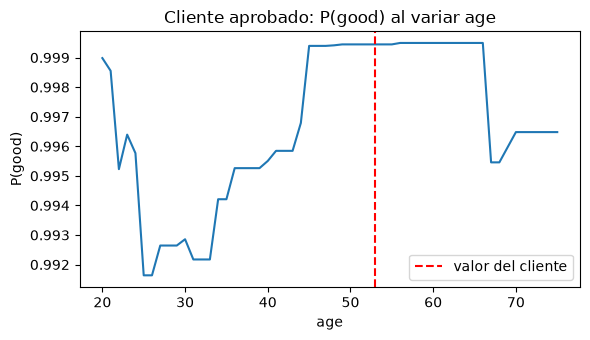

In [30]:
# Discrepancia = diferencia entre la importancia normalizada de LIME (|w|/Σ|w|) y la de SHAP (|φ|/Σ|φ|)
def norm_abs(v): v = np.abs(v); return v / v.sum()
D = pd.DataFrame({name: pd.Series(norm_abs(LIME_RES[name]["w20"]) - norm_abs(phi[i]), index=FEATURES)
                  for name, i in CLIENTS.items()})
name_b = D.abs().max().idxmax(); var_b = D[name_b].abs().idxmax(); i_b = CLIENTS[name_b]; j_b = FEATURES.index(var_b)
print(f"Mayor discrepancia: cliente {name_b} (índice {i_b}), variable {var_b}: "
      f"LIME w = {LIME_RES[name_b]['w20'][j_b]:+.4f}, SHAP φ = {phi[i_b, j_b]:+.4f}, diferencia normalizada = {D.loc[var_b, name_b]:+.4f}")

# Prueba 1: reducir sigma_rel (más localidad) y ver si la discrepancia baja
rows = []
for s_ in [0.25, 0.5, 0.75, 1.5]:
    r_ = lime_explain(X_test.iloc[i_b].values, gb, X_train.values, sigma_rel=s_)
    rows.append({"σ_rel": s_, "w LIME": r_["w20"][j_b], "|w| norm": norm_abs(r_["w20"])[j_b],
                 "|φ| norm": norm_abs(phi[i_b])[j_b], "N_ef": r_["N_ef"]})
display(pd.DataFrame(rows))

# Prueba 2: P(good) del cliente al variar solo esa variable (el resto fijo)
vals = np.sort(X_train[var_b].unique())
Xs = np.tile(X_test.iloc[i_b].values, (len(vals), 1)); Xs[:, j_b] = vals
ps_ = gb.predict_proba(pd.DataFrame(Xs, columns=FEATURES))[:, 1]
plt.figure(figsize=(6, 3.5)); plt.plot(vals, ps_, marker="o" if len(vals) < 30 else None)
plt.axvline(X_test.iloc[i_b, j_b], color="red", ls="--", label="valor del cliente")
plt.xlabel(var_b); plt.ylabel("P(good)"); plt.title(f"Cliente {name_b}: P(good) al variar {var_b}"); plt.legend(); plt.tight_layout(); plt.show()

In [31]:
# Verificación de la hipótesis de escala: LIME explicando el log-odds en vez de la probabilidad
i_b = CLIENTS["aprobado"]; j = FEATURES.index("age")
vals = np.sort(X_train["age"].unique()); Xs = np.tile(X_test.iloc[i_b].values, (len(vals), 1)); Xs[:, j] = vals
f_ = gb.decision_function(pd.DataFrame(Xs, columns=FEATURES)); p_ = 1 / (1 + np.exp(-f_))
print(f"Variando age: log-odds {f_.min():.1f} a {f_.max():.1f} (rango {f_.max()-f_.min():.1f}) | prob {p_.min():.3f} a {p_.max():.3f}")

class LogitModel:                       # envoltorio: predict_proba devuelve el log-odds
    def predict_proba(self, Z):
        f = gb.decision_function(Z); return np.c_[f, f]
r_p = lime_explain(X_test.iloc[i_b].values, gb, X_train.values)
r_l = lime_explain(X_test.iloc[i_b].values, LogitModel(), X_train.values)
nz = lambda v: np.abs(v) / np.abs(v).sum()
print(f"|age| normalizado: SHAP {nz(phi[i_b])[j]:.3f} | LIME prob {nz(r_p['w20'])[j]:.3f} | LIME log-odds {nz(r_l['w20'])[j]:.3f}")
print(f"Spearman |w| vs |phi|: prob {spearmanr(np.abs(r_p['w20']), np.abs(phi[i_b]))[0]:.2f} | log-odds {spearmanr(np.abs(r_l['w20']), np.abs(phi[i_b]))[0]:.2f}")
print(f"R²_w: prob {r_p['R2w']:.2f} | log-odds {r_l['R2w']:.2f}")

Variando age: log-odds 4.8 a 7.6 (rango 2.8) | prob 0.992 a 0.999


|age| normalizado: SHAP 0.164 | LIME prob 0.133 | LIME log-odds 0.142
Spearman |w| vs |phi|: prob 0.68 | log-odds 0.82
R²_w: prob 0.26 | log-odds 0.39


> **❓ Pregunta.** Identifique el cliente y la variable donde LIME y SHAP discrepan más. Proponga una hipótesis y pruébela con datos. ¿Se debe a localidad, no linealidad o interacción?

**Respuesta 3.5(b).**

La mayor discrepancia está en el cliente aprobado, en la variable `age`. Como LIME explica en probabilidad y SHAP en log-odds, se compararon las importancias normalizadas por la suma de cada método: `age` tiene 0.13 en LIME y 0.16 en SHAP. Es la brecha más grande de las 60 combinaciones, aunque es pequeña (≈ 3 puntos porcentuales).

La hipótesis es que se debe a la no linealidad de la sigmoide. Este cliente tiene $p \approx 1$ ($f \approx 7.5$), así que en probabilidad el modelo está saturado: `age` casi no mueve $P$(good), aunque en log-odds sí tenga peso.

Se hicieron tres pruebas:

1. **Variar `age`:** en probabilidad, la predicción solo va de 0.99 a ≈ 1.00, con un pequeño escalón cerca de los 45 años. En log-odds, va de 4.8 a 7.6.
2. **Bajar $\sigma_{rel}$ (más localidad):** la importancia de `age` en LIME solo sube de 0.13 a 0.14. La localidad no cierra la brecha.
3. **Usar LIME sobre el log-odds:** `age` sube a 0.14, el Spearman con SHAP pasa de 0.68 a 0.82 y el $R^2_w$ de 0.26 a 0.39.

La discrepancia se debe principalmente a la no linealidad, tanto por la saturación de la sigmoide como por el escalón en `age`, y no a la localidad. Como la brecha no se cierra del todo, el resto probablemente viene de interacciones que un modelo lineal no puede capturar.

### (c) Elección de $K$

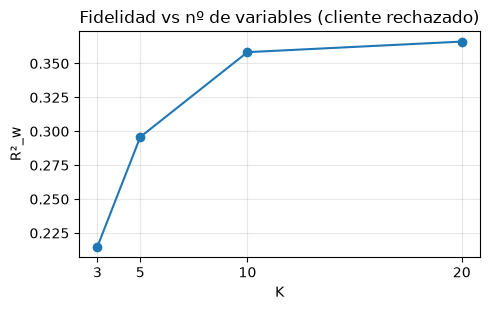

,K,R²_w
0,3,0.214922
1,5,0.295770
2,10,0.358334
3,20,0.366126


In [32]:
plt.figure(figsize=(5, 3.2)); plt.plot(T33b["K"], T33b["R²_w"], marker="o")
plt.xticks(T33b["K"]); plt.xlabel("K"); plt.ylabel("R²_w"); plt.title("Fidelidad vs nº de variables (cliente rechazado)")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()
display(T33b)

> **❓ Pregunta.** Con la tabla de $R^2_w$ según $K$, elija un $K$ y justifique (fidelidad y comprensibilidad). ¿Qué fidelidad mínima aceptaría para una decisión de crédito? ¿Qué haría si no se alcanza?

**Respuesta 3.5(c).**

| $K$ | 3 | 5 | 10 | 20 |
| :-- | :-: | :-: | :-: | :-: |
| $R^2_w$ | 0.21 | 0.30 | 0.36 | 0.37 |

Se eligió $K = 5$. Con 5 variables se obtiene cerca del 80 % de la fidelidad que da usar las 20 ($0.30 / 0.37$), y la curva casi no mejora después de $K = 10$. Además, una explicación de 5 variables se puede leer y entender de un vistazo, mientras que una de 20 no.

Para justificar una decisión de crédito, se pediría al menos $R^2_w \approx 0.8$–$0.9$. La explicación debe reproducir lo que hace el modelo, no solo aproximarlo a grandes rasgos. Aquí ningún $K$ llega ni a 0.4.

Si no se alcanza esa fidelidad, no se usaría LIME para justificar la decisión, y se reportaría el $R^2_w$ como limitación. En su lugar se usaría TreeSHAP, que suma exacto (se verificó un error de $\sim10^{-7}$), o un modelo local más flexible, como un árbol poco profundo que capture interacciones.

### (d) Contrafactuales vs top-3 $|\phi|$

In [33]:
top3 = np.argsort(-np.abs(phi[i_bad]))[:3]
changed_vars = sorted({FEATURES[c] for j in chosen for c in res_cf["changed"][j]})
print("Variables cambiadas en los contrafactuales:", changed_vars)
display(pd.DataFrame({
    "variable": [FEATURES[j] for j in top3],
    "valor": [X_test_dec.iloc[i_bad, j] for j in top3],
    "φ (log-odds)": phi[i_bad, top3],
    "inmutable": [FEATURES[j] in IMMUTABLE for j in top3],
    "accionable": [FEATURES[j] in ACTIONABLE for j in top3],
    "aparece en CFs": [FEATURES[j] in changed_vars for j in top3],
    "MAD": MADS[top3],
}))

Variables cambiadas en los contrafactuales: ['checking_status', 'credit_amount', 'duration', 'installment_commitment']


,variable,valor,φ (log-odds),inmutable,accionable,aparece en CFs,MAD
0,credit_history,all paid,-1.259218,False,False,False,0.970009
1,savings_status,>=1000,1.027097,False,True,False,0.770250
2,credit_amount,433.000000,-0.992209,False,True,True,1057.500000


> **❓ Pregunta.** Compare las variables de los contrafactuales con las tres de mayor $|\phi|$. Identifique una de $|\phi|$ alto que no aparece y explique con números por qué. ¿Qué pregunta responde SHAP y cuál el contrafactual?

**Respuesta 3.5(d).**

Las tres variables con mayor $|\phi|$ en el cliente rechazado son `credit_history` ($-1.26$), `savings_status` ($+1.03$) y `credit_amount` ($-0.99$). Los contrafactuales cambian `checking_status`, `credit_amount`, `duration` e `installment_commitment`. Solo `credit_amount` aparece en ambas listas.

`credit_history` tiene el $|\phi|$ más alto ($-1.26$ log-odds, unos $-0.27$ en probabilidad) y es la variable que más empuja hacia el rechazo, pero no aparece en ningún contrafactual. La razón es que no es accionable: describe el pasado del cliente y no se puede cambiar de forma realista. La búsqueda solo modifica las 5 variables accionables, así que en los 20 000 candidatos conserva su valor (`all paid`) y su $-1.26$ queda intacto en todos los contrafactuales.

`savings_status` tampoco aparece, pero por otra razón. Su contribución es positiva ($+1.03$) y el cliente ya está en la categoría con mayor tasa de *good* en train (≥ 1000, 0.89). Se verificó cambiando solo `savings_status` y dejando el resto fijo: con ≥ 1000 la probabilidad es 0.052, con *no known savings* (0.82 de *good* en train) baja a 0.048, y con las otras tres categorías queda en ≈ 0.01. Aplicado sobre CF1 pasa lo mismo (0.745 con ≥ 1000 y 0.731 con *no known savings*). Es decir, ningún otro valor mejora la probabilidad, y el modelo no tiene nada que ganar al cambiarla.

En cambio, `checking_status` aparece en dos contrafactuales (CF1 y CF2, con $P = 0.75$ y $0.55$) sin estar en el top-3 ($\phi = -0.58$). Es una variable barata de cambiar, porque cuesta solo 1 punto de distancia. Es decir, una variable con $|\phi|$ alto no es necesariamente una buena palanca, y una buena palanca no necesita tener $|\phi|$ alto.

Las dos herramientas responden preguntas distintas. SHAP responde *¿por qué el modelo dio esta probabilidad?*, midiendo cuánto aportó cada variable respecto al cliente promedio. El contrafactual responde *¿qué es lo mínimo y realizable que tendría que cambiar para que la decisión fuera otra?*

---
# Task 4 (Entrega Final) — Validación de Grad-CAM
## Task 4.1 · Deletion / Insertion
### Disclaimer: el código de todo el Task 4 (4.1, 4.2 y el apoyo de 4.3) fue generado con IA, detallado en AI.md. Las respuestas son mías.

In [34]:
P_STEPS, N_RANDOM = 20, 10

def gaussian_kernel1d(sigma, radius=None):
    # Kernel gaussiano 1D normalizado: k(t) ∝ exp(-t^2 / (2 σ^2)), truncado a ±3σ
    r = radius or int(3 * sigma)
    t = torch.arange(-r, r + 1, dtype=torch.float32)
    k = torch.exp(-t ** 2 / (2 * sigma ** 2))
    return k / k.sum()

def blur_reference(x, sigma=10):
    # Desenfoque gaussiano (σ = 10 px) en el espacio normalizado. Es separable: una convolución
    # horizontal y otra vertical con el mismo kernel 1D, canal por canal (groups=3), con padding reflejado.
    k = gaussian_kernel1d(sigma); r = (len(k) - 1) // 2
    kh = k.view(1, 1, 1, -1).repeat(3, 1, 1, 1); kv = k.view(1, 1, -1, 1).repeat(3, 1, 1, 1)
    out = F.conv2d(F.pad(x, (r, r, 0, 0), mode="reflect"), kh, groups=3)
    return F.conv2d(F.pad(out, (0, 0, r, r), mode="reflect"), kv, groups=3)

@torch.no_grad()
def deletion_insertion(x, c, order, mode="deletion", reference=None, P=P_STEPS):
    # order: índices (aplanados) de los 224*224 píxeles de mayor a menor importancia.
    # deletion:  en el paso k, la fracción k/P de píxeles más importantes se reemplaza por la referencia
    #            (gris = 0 en espacio normalizado, o una imagen desenfocada si se pasa `reference`).
    # insertion: se parte de la referencia (desenfoque) y en el paso k se insertan los píxeles originales
    #            de la fracción k/P más importante.
    # c_k = softmax(model(x_k))[0, c];  AUC = (1/P) Σ_{k=1..P} c_k
    n = 224 * 224
    order = torch.as_tensor(np.asarray(order), dtype=torch.long)
    if reference is None:
        reference = torch.zeros_like(x)
    curve = []
    for k in range(1, P + 1):
        m = torch.zeros(n)
        m[order[: int(round(k / P * n))]] = 1.0
        m = m.view(1, 1, 224, 224)
        xk = x * (1 - m) + reference * m if mode == "deletion" else reference * (1 - m) + x * m
        curve.append(F.softmax(model(xk), dim=1)[0, c].item())
    curve = np.array(curve)
    return curve, float(curve.mean())


Imagen (a) — espresso


,métrica,Grad-CAM,azar (media),azar (std),dif. con azar,z (σ del azar)
0,AUC deletion (↓ mejor),0.073047,0.119431,0.008512,-0.046384,-5.449349
1,AUC insertion (↑ mejor),0.854096,0.230532,0.020797,0.623565,29.982999



Imagen (b) — cup


,métrica,Grad-CAM,azar (media),azar (std),dif. con azar,z (σ del azar)
0,AUC deletion (↓ mejor),0.001912,0.027203,0.006898,-0.025291,-3.666321
1,AUC insertion (↑ mejor),0.092461,0.043822,0.007746,0.048639,6.279047



Imagen (c) — bell cote


,métrica,Grad-CAM,azar (media),azar (std),dif. con azar,z (σ del azar)
0,AUC deletion (↓ mejor),0.025099,0.008810,0.002902,0.016289,5.612317
1,AUC insertion (↑ mejor),0.258300,0.045792,0.008747,0.212508,24.294057


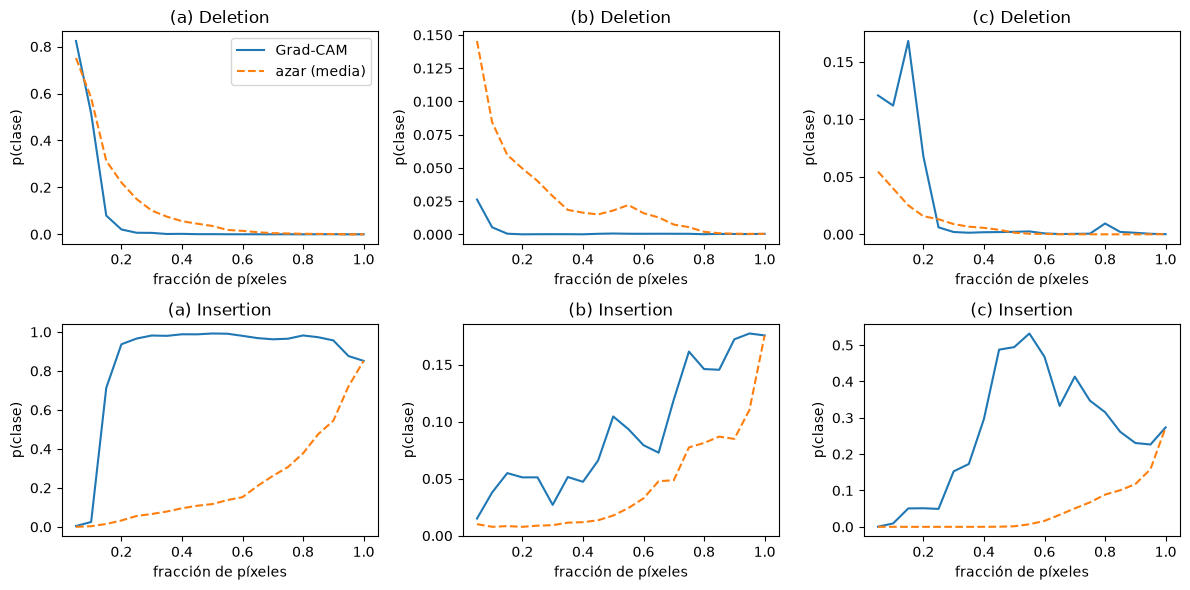

In [35]:
rng4 = np.random.RandomState(SEED)
npix = 224 * 224
ORDER_MAP, BLUR, CURVES, rows41 = {}, {}, {}, {}
for k in "abc":
    c, x = TOP1[k], x_in[k]
    ORDER_MAP[k] = np.argsort(-GC[k]["map224"].ravel(), kind="stable")       # píxeles de mayor a menor valor del mapa
    BLUR[k] = blur_reference(x)
    cd, ad = deletion_insertion(x, c, ORDER_MAP[k], "deletion")
    ci, ai = deletion_insertion(x, c, ORDER_MAP[k], "insertion", reference=BLUR[k])
    rd, ri, rcd, rci = [], [], [], []
    for _ in range(N_RANDOM):
        o = rng4.permutation(npix)
        cd_r, ad_r = deletion_insertion(x, c, o, "deletion")
        ci_r, ai_r = deletion_insertion(x, c, o, "insertion", reference=BLUR[k])
        rd.append(ad_r); ri.append(ai_r); rcd.append(cd_r); rci.append(ci_r)
    CURVES[k] = dict(del_map=cd, ins_map=ci, del_rand=np.mean(rcd, 0), ins_rand=np.mean(rci, 0))
    rows41[k] = pd.DataFrame({
        "métrica": ["AUC deletion (↓ mejor)", "AUC insertion (↑ mejor)"],
        "Grad-CAM": [ad, ai], "azar (media)": [np.mean(rd), np.mean(ri)], "azar (std)": [np.std(rd), np.std(ri)],
        "dif. con azar": [ad - np.mean(rd), ai - np.mean(ri)],
        "z (σ del azar)": [(ad - np.mean(rd)) / np.std(rd), (ai - np.mean(ri)) / np.std(ri)]})
    print(f"\nImagen ({k}) — {CLASSES[c]}"); display(rows41[k])

fig, axes = plt.subplots(2, 3, figsize=(12, 6)); ks = np.arange(1, P_STEPS + 1) / P_STEPS
for j, k in enumerate("abc"):
    for r_, (nm, lbl) in enumerate([("del", "Deletion"), ("ins", "Insertion")]):
        axes[r_, j].plot(ks, CURVES[k][nm + "_map"], label="Grad-CAM"); axes[r_, j].plot(ks, CURVES[k][nm + "_rand"], "--", label="azar (media)")
        axes[r_, j].set_title(f"({k}) {lbl}"); axes[r_, j].set_xlabel("fracción de píxeles"); axes[r_, j].set_ylabel("p(clase)")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

## Task 4.2 · Aleatorización de parámetros en cascada


In [36]:
CASCADE = ["fc", "layer4", "layer3", "layer2", "layer1", "conv1"]

def reinit_module(module):
    # Reinicializa con la inicialización por defecto de PyTorch (reset_parameters de cada submódulo).
    for m in module.modules():
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()

m_casc = resnet18().to(DEVICE).eval(); m_casc.load_state_dict(model.state_dict())   # copia sin hooks
torch.manual_seed(SEED)
orig_L7 = {k: GC[k]["L7"].flatten().numpy() for k in "abc"}
rho_tab = {k: [] for k in "abc"}
for stage in CASCADE:
    reinit_module(getattr(m_casc, stage)); m_casc.eval()          # reinit acumulativo
    gc_c = GradCAM(m_casc, m_casc.layer4)
    for k in "abc":
        L7_new = gc_c(x_in[k], TOP1[k])["L7"].flatten().numpy()   # clase top-1 ORIGINAL, no la nueva predicción
        rho_tab[k].append(spearmanr(orig_L7[k], L7_new)[0])       # NaN si el mapa nuevo es constante (todo 0 tras ReLU)
    gc_c.remove()
T42 = pd.DataFrame(rho_tab, index=[f"+ {s}" for s in CASCADE]).T
T42.index = [f"({k})" for k in "abc"]
display(T42)
for k in "abc":
    first = next((s for s, r in zip(CASCADE, T42.loc[f"({k})"]) if not r >= 0.3), "nunca")
    print(f"Imagen ({k}): Spearman < 0.3 por primera vez en la etapa: {first}")

,+ fc,+ layer4,+ layer3,+ layer2,+ layer1,+ conv1
(a),-0.006958,0.179490,-0.001594,-0.236276,0.073538,-0.036954
(b),0.281946,0.347754,0.165085,0.381006,0.198236,-0.092556
(c),-0.430822,0.304632,0.051603,0.167074,0.294406,0.183716


Imagen (a): Spearman < 0.3 por primera vez en la etapa: fc
Imagen (b): Spearman < 0.3 por primera vez en la etapa: fc
Imagen (c): Spearman < 0.3 por primera vez en la etapa: fc


## Task 4.3 · Preguntas


### (a) Grad-CAM vs azar, forma de las curvas, referencia desenfocada

In [37]:
for k in "abc":
    print(f"({k}) z deletion = {rows41[k]['z (σ del azar)'][0]:+.2f} σ | z insertion = {rows41[k]['z (σ del azar)'][1]:+.2f} σ")

# Deletion en (a) con referencia desenfocada en lugar de gris
x_a, c_a = x_in["a"], TOP1["a"]
_, auc_del_gray = deletion_insertion(x_a, c_a, ORDER_MAP["a"], "deletion")
_, auc_del_blur = deletion_insertion(x_a, c_a, ORDER_MAP["a"], "deletion", reference=BLUR["a"])
rand_blur = [deletion_insertion(x_a, c_a, rng4.permutation(npix), "deletion", reference=BLUR["a"])[1] for _ in range(N_RANDOM)]
display(pd.DataFrame({"referencia": ["gris", "desenfocada"], "AUC_del Grad-CAM": [auc_del_gray, auc_del_blur],
                      "azar (media)": [rows41["a"]["azar (media)"][0], np.mean(rand_blur)],
                      "azar (std)": [rows41["a"]["azar (std)"][0], np.std(rand_blur)]}))

(a) z deletion = -5.45 σ | z insertion = +29.98 σ
(b) z deletion = -3.67 σ | z insertion = +6.28 σ
(c) z deletion = +5.61 σ | z insertion = +24.29 σ


,referencia,AUC_del Grad-CAM,azar (media),azar (std)
0,gris,0.073047,0.119431,0.008512
1,desenfocada,0.222508,0.183492,0.028345


In [38]:
# Verificación: deletion en (c) con un azar por bloques de 32x32 (celdas del mapa 7x7) en vez de píxeles sueltos
x, c = x_in["c"], TOP1["c"]
rb = np.random.RandomState(0); a_pix, a_blk = [], []
for _ in range(10):
    a_pix.append(deletion_insertion(x, c, rb.permutation(224 * 224), "deletion")[1])
    cm = np.zeros((224, 224))
    for rank, ci in enumerate(rb.permutation(49)):
        cm[(ci // 7) * 32:(ci // 7 + 1) * 32, (ci % 7) * 32:(ci % 7 + 1) * 32] = 49 - rank
    a_blk.append(deletion_insertion(x, c, np.argsort(-(cm + 1e-3 * rb.rand(224, 224)).ravel()), "deletion")[1])
print(f"AUC_del imagen (c): azar píxeles sueltos {np.mean(a_pix):.3f}±{np.std(a_pix):.3f} | azar por bloques {np.mean(a_blk):.3f}±{np.std(a_blk):.3f} | Grad-CAM {rows41['c']['Grad-CAM'][0]:.3f}")

AUC_del imagen (c): azar píxeles sueltos 0.007±0.001 | azar por bloques 0.067±0.032 | Grad-CAM 0.025


> **❓ Pregunta.** ¿Grad-CAM supera al azar en deletion e insertion y por cuántas desviaciones estándar? Explique la forma de las curvas (mapa $7\times7$). Repita deletion en la imagen (a) con referencia desenfocada en vez de gris y compare los AUC.

**Respuesta 4.3(a).**

En insertion, Grad-CAM supera al azar en las tres imágenes, por $+30\sigma$ (a), $+6\sigma$ (b) y $+24\sigma$ (c). En deletion, menor es mejor: el AUC queda por debajo del azar en (a) por $5\sigma$ y en (b) por $4\sigma$. En (c) parece peor que el azar ($+6\sigma$), pero esto es un artefacto de la comparación, como se explica abajo.

Las curvas son abruptas, casi escalonadas. Como el mapa tiene solo $7\times7 = 49$ celdas, cada paso de 5 % de píxeles equivale a ≈ 2.5 celdas. En (a), quitar el 20 % de píxeles más importantes ya baja la probabilidad a ≈ 0, e insertarlos la sube a ≈ 0.94. El mapa ordena bloques grandes, no píxeles individuales.

En (c), el mapa señala el fondo (ver 1.4(c)). El azar por píxeles sueltos genera ruido que el modelo nunca vio, y eso hunde la probabilidad de cualquier clase (AUC ≈ 0.007). Si el azar se hace por bloques de $32\times32$, que es una comparación más justa, su AUC es ≈ $0.07 \pm 0.03$. Grad-CAM (≈ 0.025) queda por debajo, es decir, mejor que el azar, aunque sin una diferencia clara ($\approx -1.3\sigma$).

Con referencia desenfocada en la imagen (a), el AUC de deletion sube de ≈ 0.07 (gris) a ≈ 0.22. El azar con desenfoque da ≈ $0.18 \pm 0.03$, así que $z \approx +1.4$: con desenfoque, Grad-CAM ya no supera al azar. Deletion depende mucho de la referencia: los parches grises son ruido que derrumba la probabilidad con facilidad, mientras que el desenfoque conserva el color y las formas generales.

### (b) Cascada y predicción para `fc` aleatorizado

In [39]:
display(T42)
# Verificación de la predicción: con solo fc aleatorizado, α_k^c debería ser w'_k^c / Z (con los NUEVOS pesos)
m_fc = resnet18().to(DEVICE).eval(); m_fc.load_state_dict(model.state_dict())
torch.manual_seed(SEED); reinit_module(m_fc.fc); m_fc.eval()
gc_fc = GradCAM(m_fc, m_fc.layer4); out_fc = gc_fc(x_in["a"], TOP1["a"]); gc_fc.remove()
w_new = m_fc.fc.weight.detach()[TOP1["a"]]
print("Máx |α − w'/Z| con fc aleatorizado (imagen a):", (out_fc["alpha"] - w_new / Z).abs().max().item())

,+ fc,+ layer4,+ layer3,+ layer2,+ layer1,+ conv1
(a),-0.006958,0.179490,-0.001594,-0.236276,0.073538,-0.036954
(b),0.281946,0.347754,0.165085,0.381006,0.198236,-0.092556
(c),-0.430822,0.304632,0.051603,0.167074,0.294406,0.183716


Máx |α − w'/Z| con fc aleatorizado (imagen a): 1.7462298274040222e-10


> **❓ Pregunta.** ¿En qué etapa de la cascada cae el Spearman por debajo de 0.3 en cada imagen? Dado que $\alpha_k^c=w_k^c/Z$, prediga qué pasa con el mapa cuando solo se aleatoriza `fc` y compare con la primera etapa.

**Respuesta 4.3(b).**

En las tres imágenes, el Spearman cae por debajo de 0.3 desde la primera etapa (`fc`): $-0.01$ en (a), $0.28$ en (b) y $-0.43$ en (c).

Esto es lo que se esperaba. Como $\alpha_k^c = w_k^c/Z$, si `fc` tiene pesos aleatorios $w'$, el mapa pasa a ser $\mathrm{ReLU}\big(\sum_k w'_k A^k / Z\big)$, es decir, una combinación aleatoria de canales, así que el Spearman debería ser ≈ 0. Esto se verificó numéricamente: $\max|\alpha - w'/Z| \sim 10^{-10}$.

El ruido de ±0.14 es la dispersión de la correlación entre dos mapas sin relación con 49 celdas ($1/\sqrt{48}$). Con eso, (a) coincide con la predicción y (b) queda cerca (2 desviaciones). En cambio, (c) con $-0.43$ está a ≈ 3 desviaciones de 0, o sea que no es ≈ 0: el mapa aleatorio ilumina justo lo que el original apagaba (con una sola semilla no se sabe si es real). Además, la cascada no es monótona: (b) vuelve a superar 0.3 en `layer4` (0.35) y `layer2` (0.38).

El método pasa la prueba de sensatez, porque el mapa depende de los pesos aprendidos. Pero en este ResNet toda la información de clase pasa por `fc`, así que la prueba no permite saber si las capas convolucionales aportan algo por su cuenta.


### (c) Audiencias y riesgo de contrafactuales (sin código)

> **❓ Pregunta.** Para el modelo de crédito, indique qué explicación entregaría a (i) la persona solicitante, (ii) un oficial de cumplimiento y (iii) un regulador, con qué validaciones respaldadas por sus números y qué no entregaría. ¿Por qué un contrafactual como el de 3.4 sería un riesgo en un sistema de detección de lavado (Proyecto 2) y qué entregaría en su lugar?

**Respuesta 4.3(c).**

Como contexto, el modelo es modesto: exactitud ≈ 0.78 y AUC ≈ 0.77.

| Audiencia | Entregaría | Validación | No entregaría |
| :-- | :-- | :-- | :-- |
| **Solicitante** | Las 2–3 razones principales en palabras (TreeSHAP) y, solo si se revisa que sea realista y robusto, un contrafactual (no CF1, ver abajo) | SHAP suma exacto (error $\sim10^{-7}$); el CF se verificó con el modelo ($P \geq 0.5$), lo que solo prueba que cruza el umbral | Valores $\phi$ en log-odds; LIME ($R^2_w \approx 0.3$); CF1 tal cual; `credit_history` como algo que se pueda cambiar |
| **Oficial de cumplimiento** | Cascada por cliente, beeswarm global y comparación SHAP vs permutación | SHAP suma exacto ($\sim10^{-7}$); Shapley a mano coincide con `shap` ($\sim10^{-8}$); Spearman SHAP–permutación ≈ 0.70 | LIME como justificación principal; importancias con variables duplicadas sin advertirlo (bajan de ≈ 0.49 a ≈ 0.30) |
| **Regulador** | Documentación completa: TreeSHAP global y local, límites de los datos y revisión de variables protegidas (`age` aporta $+1.09$ al aprobado) | Las anteriores, más estabilidad (Jaccard 1.0 con $N \geq 2000$) y pruebas de sensatez | Contrafactuales como prueba de causalidad; explicaciones sin su fidelidad reportada |

Sobre CF1 (3.4), no se entregaría tal cual: pide cerrar la cuenta corriente y pedir 7 unidades menos, lo cual no es realista, y el cambio de monto solo funciona porque cae en un corte de los árboles. CF2 tampoco sirve de alternativa, porque es estrictamente peor (los mismos cambios más `duration`, con $P = 0.55$ frente a 0.75).

En un sistema de detección de lavado, un contrafactual le diría al sospechoso exactamente qué cambiar para no ser detectado, por ejemplo, fraccionar montos por debajo de cierto umbral. Sería una guía para evadir el sistema, y además le revelaría que está siendo investigado.

En su lugar, a los analistas internos se les darían atribuciones tipo SHAP que muestren qué señales generaron la alerta, con acceso restringido. Al cliente se le daría solo un aviso genérico, sin umbrales ni variables. Al regulador se le daría una validación global del modelo, con explicaciones agregadas y pruebas de sensatez.